# Intelligence Artificielle pour HumanForYou

## 1. Importation des bibliothèques

La bibliothèque pandas est utilisée pour manipuler des DataFrames, facilitant l’analyse de données tabulaires. missingno permet de visualiser les valeurs manquantes, tandis que seaborn améliore la lisibilité des graphiques basés sur matplotlib.

Le module sklearn offre plusieurs outils de machine learning. SimpleImputer gère les valeurs manquantes, StandardScaler normalise les données, et OneHotEncoder encode les variables catégorielles. LabelEncoder transforme les étiquettes en valeurs numériques, et train_test_split divise les données en ensembles d'entraînement et de test.

Nous utilisons plusieurs modèles de classification : LogisticRegression, Perceptron, SVC, GaussianNB, DecisionTreeClassifier, RandomForestClassifier et KNeighborsClassifier.

Pour évaluer les performances, confusion_matrix, classification_report, roc_auc_score, precision_score, recall_score, f1_score et accuracy_score. Les courbes ROC et précision-rappel sont également disponibles.

Enfin, numpy gère les calculs numériques, et time mesure le temps d'exécution. BayesSearchCV optimise les hyperparamètres grâce à l’optimisation bayésienne, avec les espaces Integer, Categorical, Real.

Le code suivant constitue un environnement complet pour le prétraitement, l’analyse et la modélisation des données.

In [8]:
%pip install scikit-optimize

  Obtaining dependency information for scikit-optimize from https://files.pythonhosted.org/packages/65/cd/15c9ebea645cc9860aa71fe0474f4be981f10ed8e19e1fb0ef1027d4966e/scikit_optimize-0.10.2-py2.py3-none-any.whl.metadata
  Obtaining dependency information for pyaml>=16.9 from https://files.pythonhosted.org/packages/a8/ee/a878f2ad010cbccb311f947f0f2f09d38f613938ee28c34e60fceecc75a1/pyaml-25.7.0-py3-none-any.whl.metadata
  Obtaining dependency information for PyYAML from https://files.pythonhosted.org/packages/da/e3/ea007450a105ae919a72393cb06f122f288ef60bba2dc64b26e2646fa315/pyyaml-6.0.3-cp311-cp311-win_amd64.whl.metadata
   ---------------------------------------- 0.0/107.8 kB ? eta -:--:--
   ---------------------------------- ----- 92.2/107.8 kB 2.6 MB/s eta 0:00:01
   ---------------------------------------- 107.8/107.8 kB 3.1 MB/s eta 0:00:00
   ---------------------------------------- 0.0/158.8 kB ? eta -:--:--
   ------------------------------ --------- 122.9/158.8 kB 3.6 MB/s eta


[notice] A new release of pip is available: 23.2.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import pandas as pd
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve, precision_recall_curve, precision_score, recall_score, f1_score, accuracy_score, make_scorer
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
import numpy as np
import time
from skopt import BayesSearchCV
from skopt.space import Integer, Categorical, Real

## 2. Importation des données

### Données générales

Le service Ressources Humaines nous a transmis un fichier CSV contenant des données anonymisées sur les employés. Ce dataset regroupe plusieurs informations relatives aux collaborateurs de l’entreprise en 2015, ainsi que leur statut en 2016 (notamment s’ils ont quitté l’entreprise ou non).

Il inclut des caractéristiques démographiques (âge, sexe, statut marital), des informations professionnelles (métier, niveau hiérarchique, ancienneté, expérience), ainsi que des données financières et de performance (salaire, augmentation, stock-options, nombre de formations suivies). Certains champs sont catégoriels (domaine d’étude, fréquence des voyages professionnels), tandis que d’autres sont numériques (distance domicile-travail, nombre d’années avec le manager actuel, etc.).

In [10]:
# Charger le dataset
general_data = pd.read_csv('Data/general_data.csv')

# Afficher les premières lignes du dataset
general_data.head()

,Age,Attrition,BusinessTravel,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeID,Gender,...,NumCompaniesWorked,Over18,PercentSalaryHike,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsSinceLastPromotion,YearsWithCurrManager
0,51,No,Travel_Rarely,Sales,6,2,Life Sciences,1,1,Female,...,1.0,Y,11,8,0,1.0,6,1,0,0
1,31,Yes,Travel_Frequently,Research & Development,10,1,Life Sciences,1,2,Female,...,0.0,Y,23,8,1,6.0,3,5,1,4
2,32,No,Travel_Frequently,Research & Development,17,4,Other,1,3,Male,...,1.0,Y,15,8,3,5.0,2,5,0,3
3,38,No,Non-Travel,Research & Development,2,5,Life Sciences,1,4,Male,...,3.0,Y,11,8,3,13.0,5,8,7,5
4,32,No,Travel_Rarely,Research & Development,10,1,Medical,1,5,Male,...,4.0,Y,12,8,2,9.0,2,6,0,4


In [11]:
# Afficher les informations du dataset
general_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      4410 non-null   int64  
 1   Attrition                4410 non-null   str    
 2   BusinessTravel           4410 non-null   str    
 3   Department               4410 non-null   str    
 4   DistanceFromHome         4410 non-null   int64  
 5   Education                4410 non-null   int64  
 6   EducationField           4410 non-null   str    
 7   EmployeeCount            4410 non-null   int64  
 8   EmployeeID               4410 non-null   int64  
 9   Gender                   4410 non-null   str    
 10  JobLevel                 4410 non-null   int64  
 11  JobRole                  4410 non-null   str    
 12  MaritalStatus            4410 non-null   str    
 13  MonthlyIncome            4410 non-null   int64  
 14  NumCompaniesWorked       4391 non-n

In [12]:
# Display summary statistics
general_data.describe()

,Age,DistanceFromHome,Education,EmployeeCount,EmployeeID,JobLevel,MonthlyIncome,NumCompaniesWorked,PercentSalaryHike,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsSinceLastPromotion,YearsWithCurrManager
count,4410.000000,4410.000000,4410.000000,4410.0,4410.000000,4410.000000,4410.000000,4391.000000,4410.000000,4410.0,4410.000000,4401.000000,4410.000000,4410.000000,4410.000000,4410.000000
mean,36.923810,9.192517,2.912925,1.0,2205.500000,2.063946,65029.312925,2.694830,15.209524,8.0,0.793878,11.279936,2.799320,7.008163,2.187755,4.123129
std,9.133301,8.105026,1.023933,0.0,1273.201673,1.106689,47068.888559,2.498887,3.659108,0.0,0.851883,7.782222,1.288978,6.125135,3.221699,3.567327
min,18.000000,1.000000,1.000000,1.0,1.000000,1.000000,10090.000000,0.000000,11.000000,8.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,2.000000,2.000000,1.0,1103.250000,1.000000,29110.000000,1.000000,12.000000,8.0,0.000000,6.000000,2.000000,3.000000,0.000000,2.000000
50%,36.000000,7.000000,3.000000,1.0,2205.500000,2.000000,49190.000000,2.000000,14.000000,8.0,1.000000,10.000000,3.000000,5.000000,1.000000,3.000000
75%,43.000000,14.000000,4.000000,1.0,3307.750000,3.000000,83800.000000,4.000000,18.000000,8.0,1.000000,15.000000,3.000000,9.000000,3.000000,7.000000
max,60.000000,29.000000,5.000000,1.0,4410.000000,5.000000,199990.000000,9.000000,25.000000,8.0,3.000000,40.000000,6.000000,40.000000,15.000000,17.000000


In [13]:
# Identifie le type des colonnes (entre numérique et catégorique)
numerical_columns = general_data.select_dtypes(include=['float64', 'int64']).columns
categorical_columns = general_data.select_dtypes(include=['object']).columns
print('numerical_columns : ', numerical_columns)
print('categorical columns : ', categorical_columns)

numerical_columns :  Index(['Age', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeID',
       'JobLevel', 'MonthlyIncome', 'NumCompaniesWorked', 'PercentSalaryHike',
       'StandardHours', 'StockOptionLevel', 'TotalWorkingYears',
       'TrainingTimesLastYear', 'YearsAtCompany', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='str')
categorical columns :  Index(['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender',
       'JobRole', 'MaritalStatus', 'Over18'],
      dtype='str')


C:\Users\Agordien\AppData\Local\Temp\ipykernel_31368\2780197165.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = general_data.select_dtypes(include=['object']).columns


#### Vérfication du nombre de valeur null (manquante)

Avant d’exploiter les données, il est essentiel de gérer les valeurs manquantes, qui pourraient fausser les analyses. La première étape consiste à identifier ces valeurs en comptant les entrées nulles dans le dataset.

Pour visualiser leur répartition, on utilise la bibliothèque missingno, qui permet d’avoir un aperçu graphique des données absentes. Ensuite, différentes stratégies d’imputation sont appliquées :

Pour les variables numériques, les valeurs manquantes sont remplacées par la médiane de chaque colonne, une méthode robuste aux valeurs extrêmes.
Pour les variables catégorielles, l’imputation se fait avec la valeur la plus fréquente (modale), assurant ainsi une continuité logique dans les données.
Après ces transformations, un dernier contrôle est effectué pour s’assurer qu’il ne reste plus de valeurs manquantes. Cette étape garantit un dataset plus complet et fiable pour les analyses futures.

In [14]:
# Afficher les valeurs manquantes
general_data.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeID                  0
Gender                      0
JobLevel                    0
JobRole                     0
MaritalStatus               0
MonthlyIncome               0
NumCompaniesWorked         19
Over18                      0
PercentSalaryHike           0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           9
TrainingTimesLastYear       0
YearsAtCompany              0
YearsSinceLastPromotion     0
YearsWithCurrManager        0
dtype: int64

#### Remplissage des valeurs vide

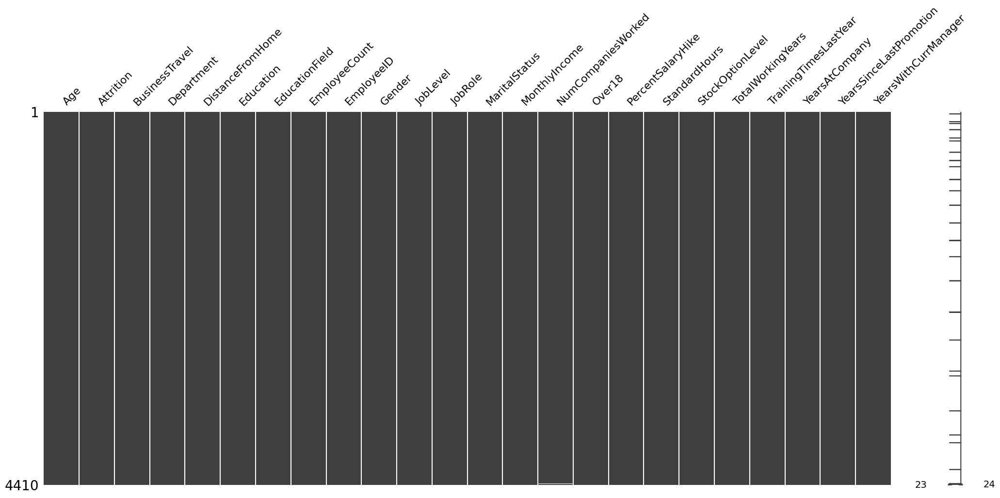

C:\Users\Agordien\AppData\Local\Temp\ipykernel_31368\515402886.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = general_data.select_dtypes(include=['object']).columns


Age                        0
DistanceFromHome           0
Education                  0
EmployeeCount              0
EmployeeID                 0
JobLevel                   0
MonthlyIncome              0
NumCompaniesWorked         0
PercentSalaryHike          0
StandardHours              0
StockOptionLevel           0
TotalWorkingYears          0
TrainingTimesLastYear      0
YearsAtCompany             0
YearsSinceLastPromotion    0
YearsWithCurrManager       0
Attrition                  0
BusinessTravel             0
Department                 0
EducationField             0
Gender                     0
JobRole                    0
MaritalStatus              0
Over18                     0
dtype: int64

In [16]:
# Visualize missing data
msno.matrix(general_data)
plt.show()
general_data_updated = general_data.copy()

# Impute missing values
imputer = SimpleImputer(strategy="median")

general_data_num = general_data_updated.select_dtypes(include=[np.number])
imputer.fit(general_data_num)

# Remplacement des valeurs manquantes
general_data_updated = pd.DataFrame(imputer.transform(general_data_num), columns=general_data_num.columns)

# For categorical columns, use mode imputation
categorical_columns = general_data.select_dtypes(include=['object']).columns
general_data_updated[categorical_columns] = general_data[categorical_columns].fillna(general_data[categorical_columns].mode().iloc[0])

# Vérifier s'il reste des valeurs manquantes
general_data_updated.isnull().sum()

#### Analyse des données

##### Analyse univariée

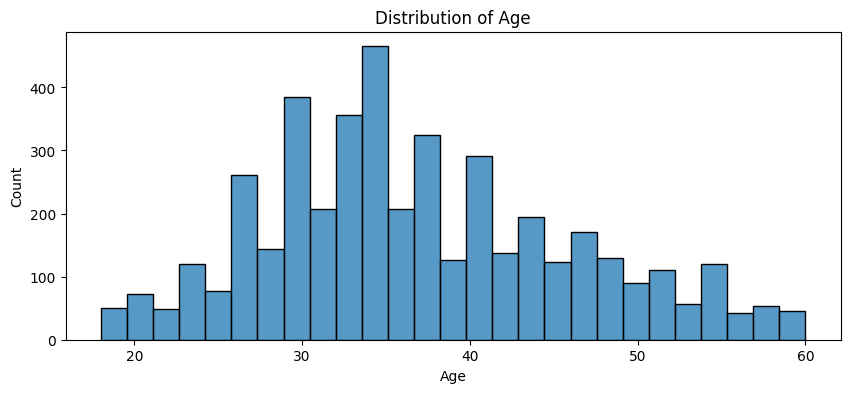

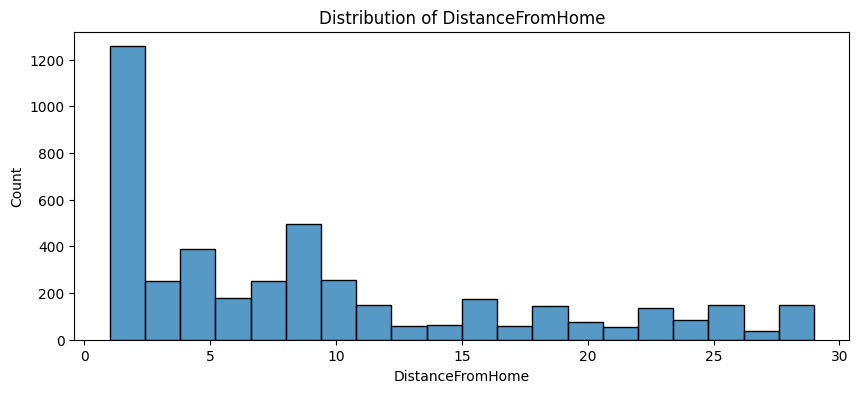

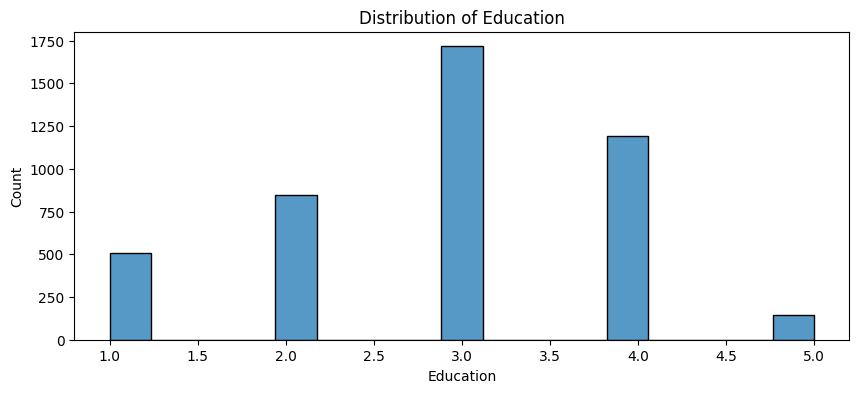

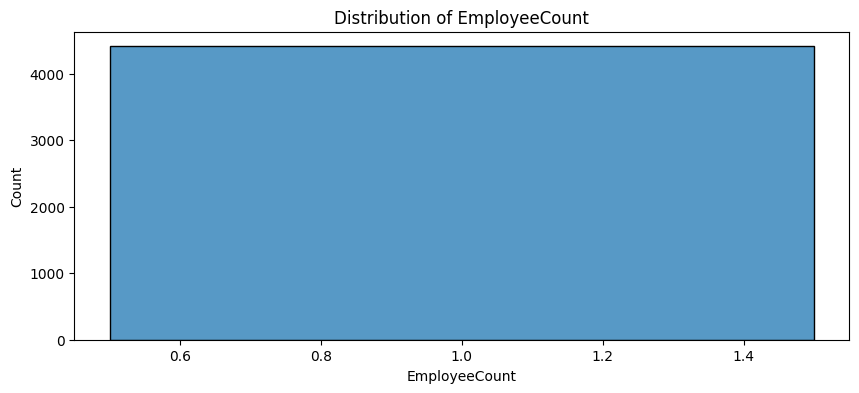

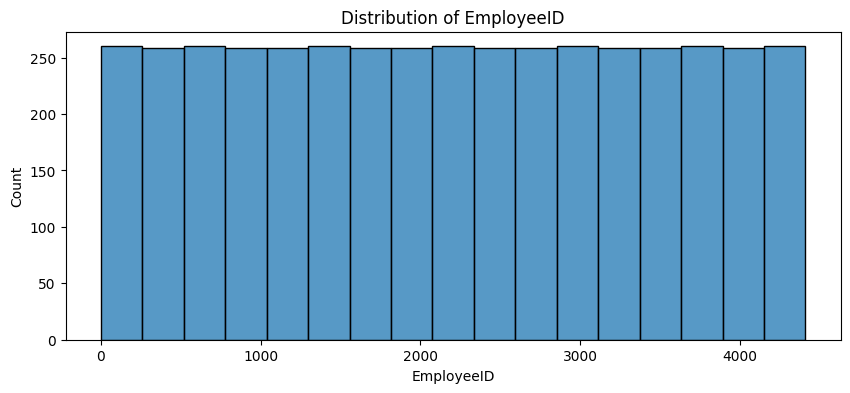

...

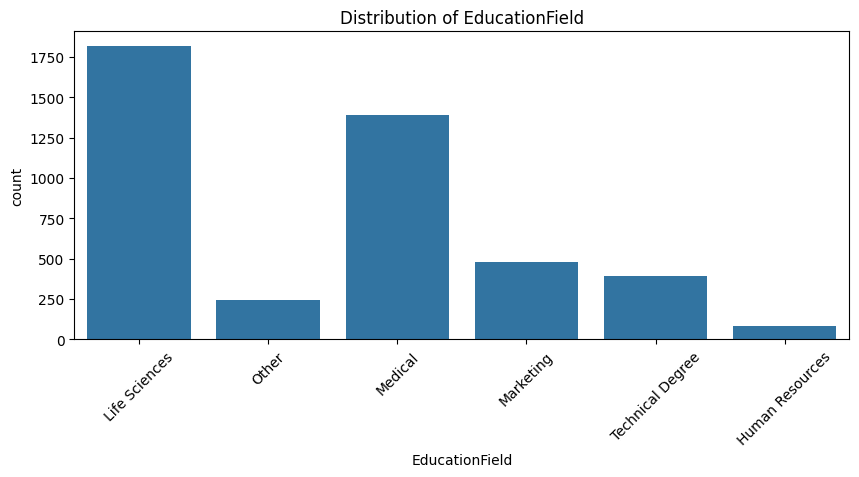

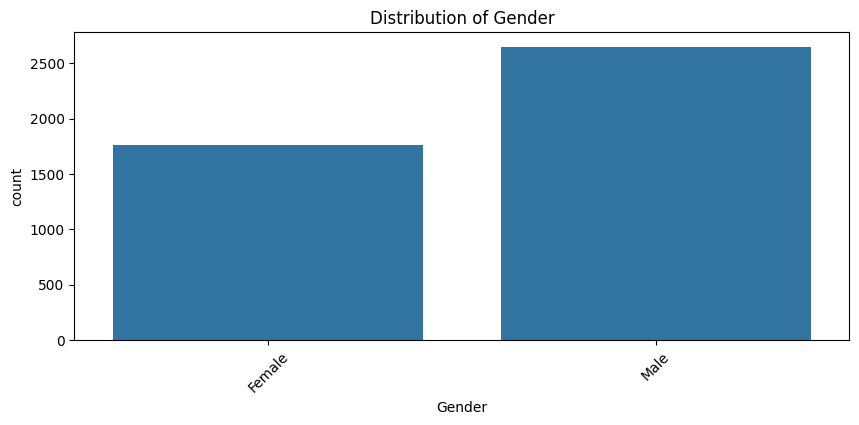

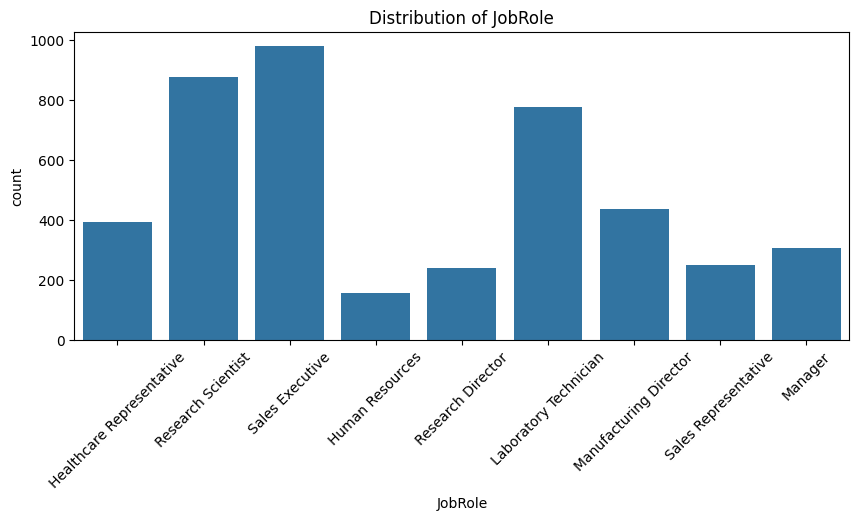

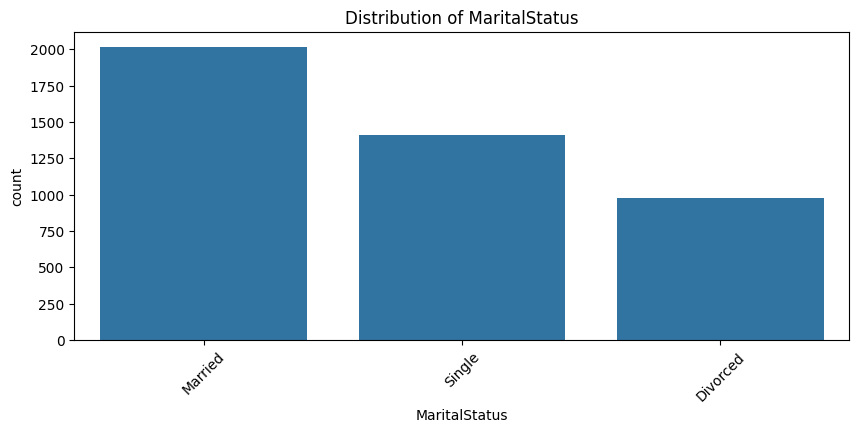

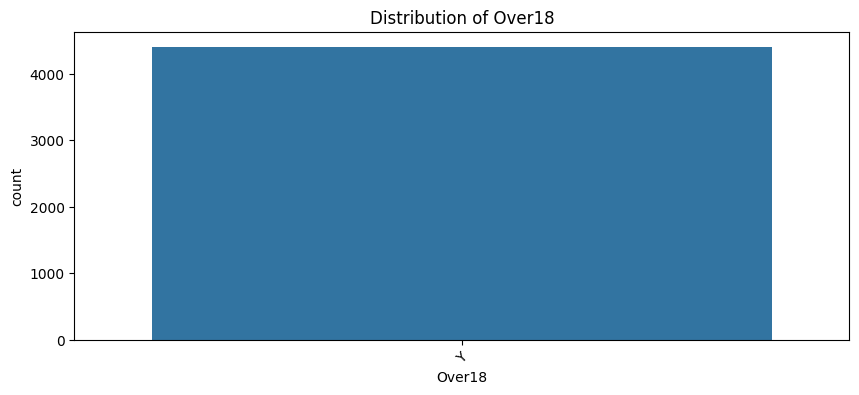

In [17]:
# Univariate analysis for numerical features
for column in numerical_columns:
    plt.figure(figsize=(10, 4))
    sns.histplot(x=general_data_updated[column])
    plt.title(f'Distribution of {column}')
    plt.show()
    
# Univariate analysis for categorical features
for column in categorical_columns:
    plt.figure(figsize=(10, 4))
    sns.countplot(x=general_data_updated[column])
    plt.title(f'Distribution of {column}')
    plt.xticks(rotation=45)
    plt.show()

##### Analyse bivariée

<Figure size 2000x400 with 0 Axes>

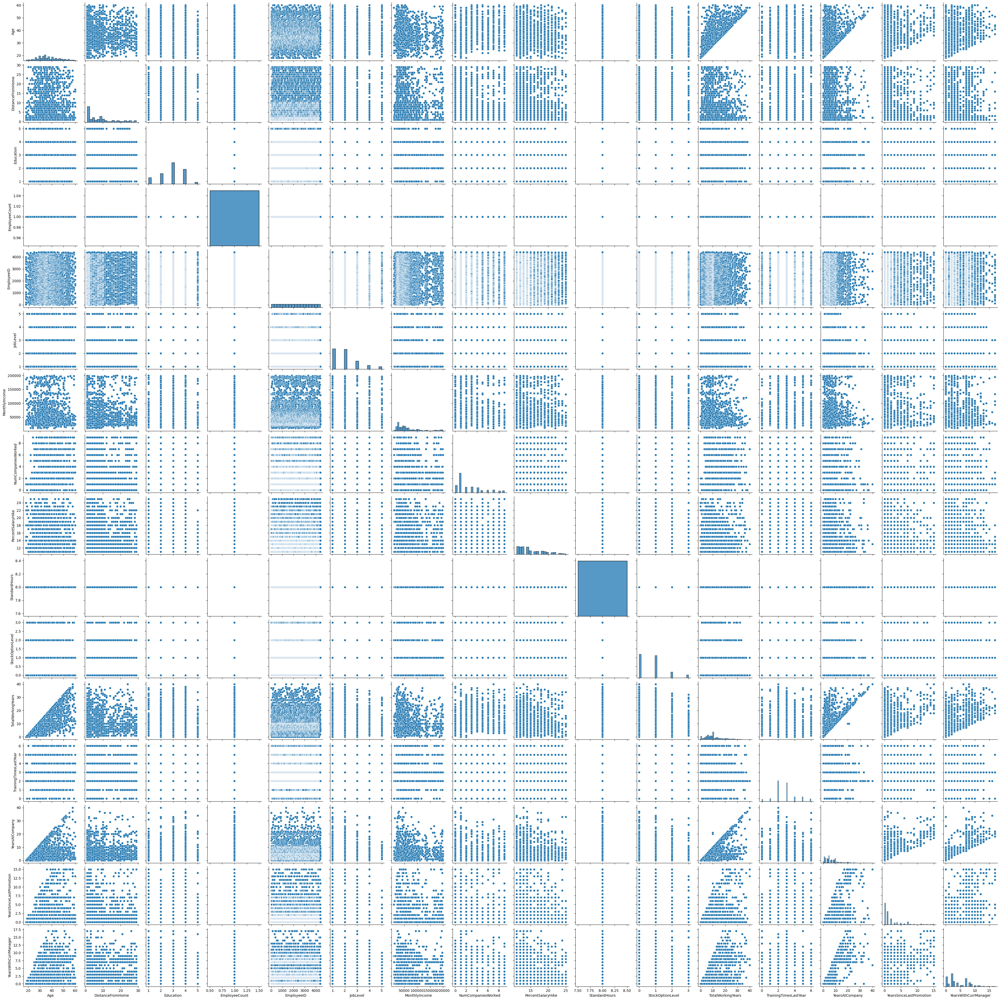

In [18]:
plt.figure(figsize=(20, 4))
sns.pairplot(general_data_updated[numerical_columns])
plt.show()

##### Analyse par Boite à moustache 

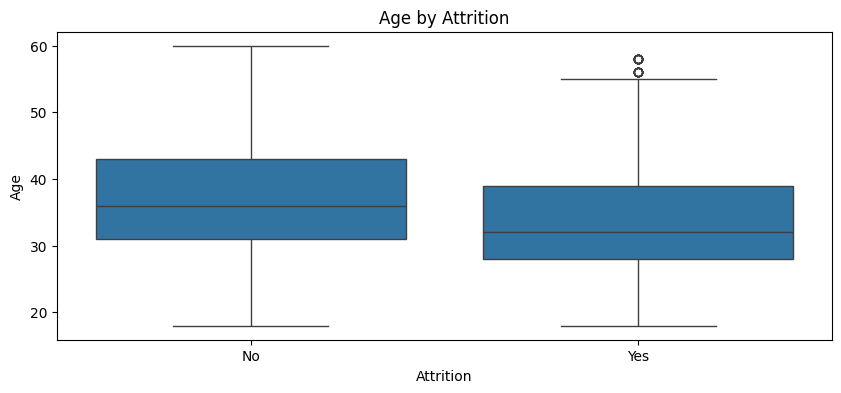

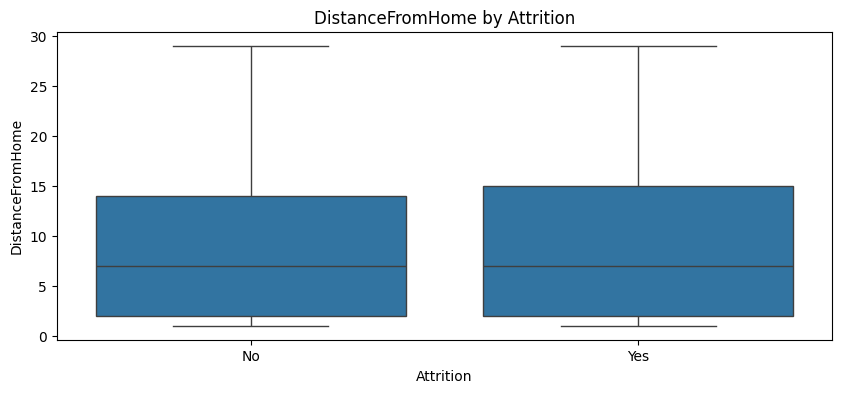

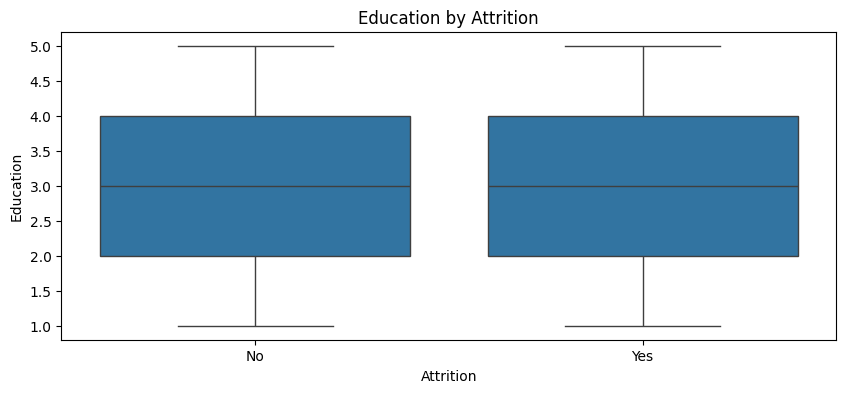

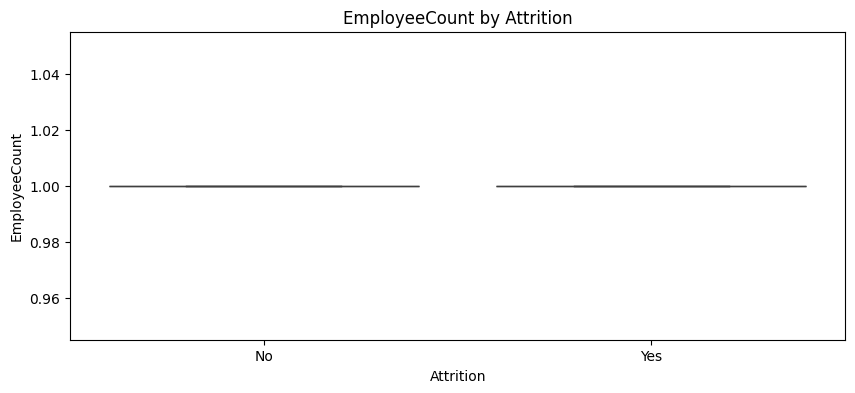

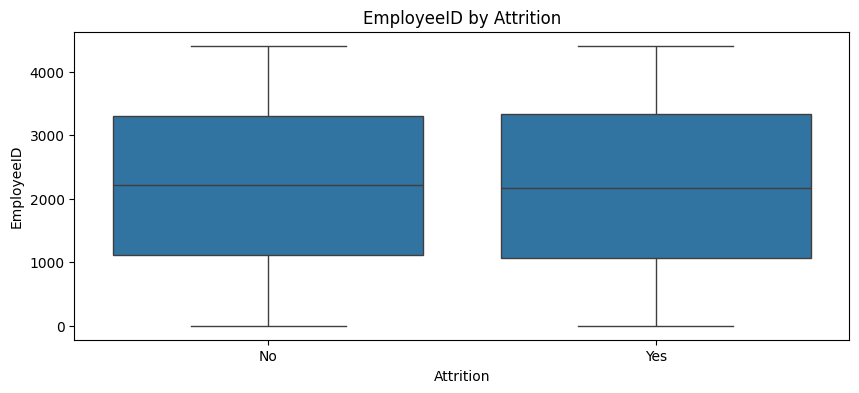

...

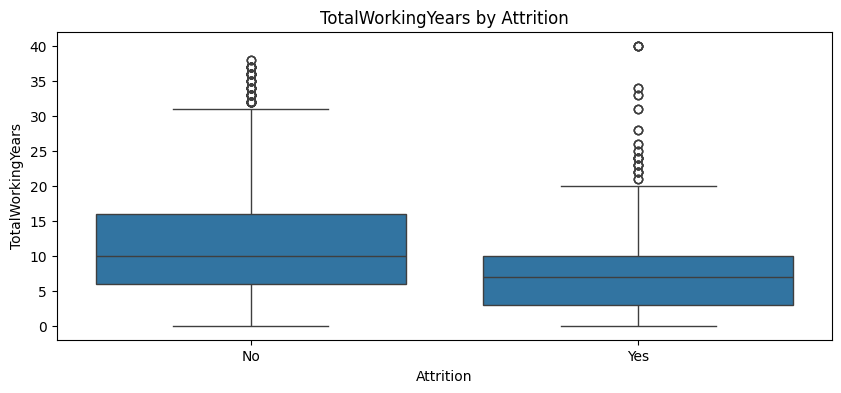

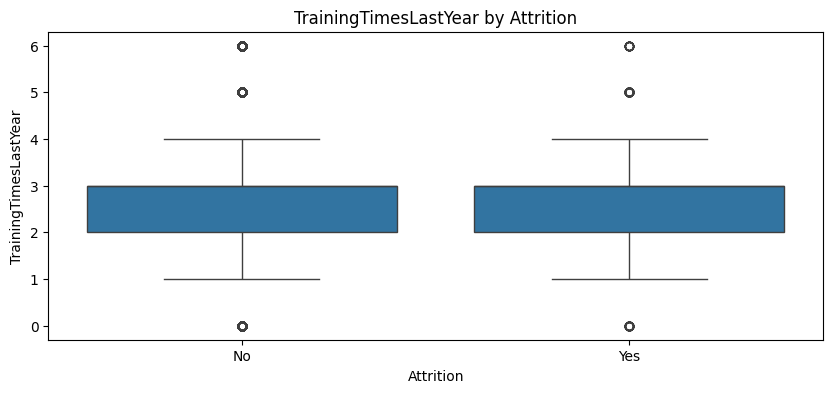

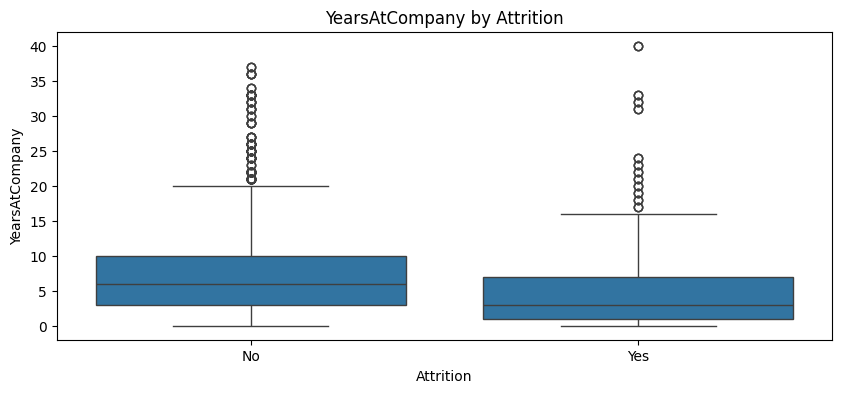

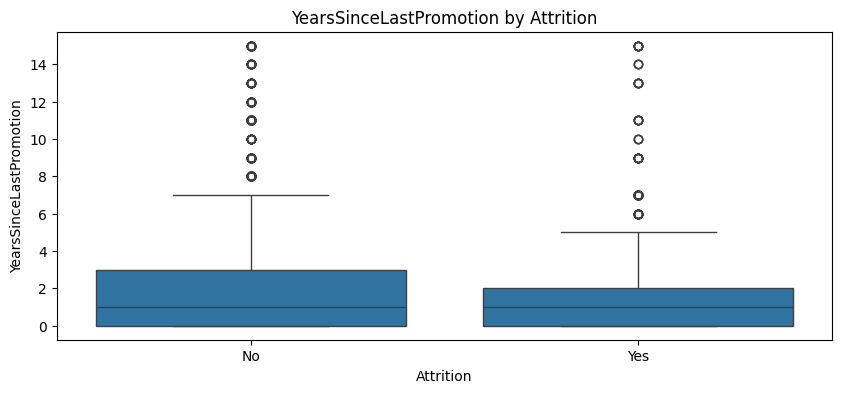

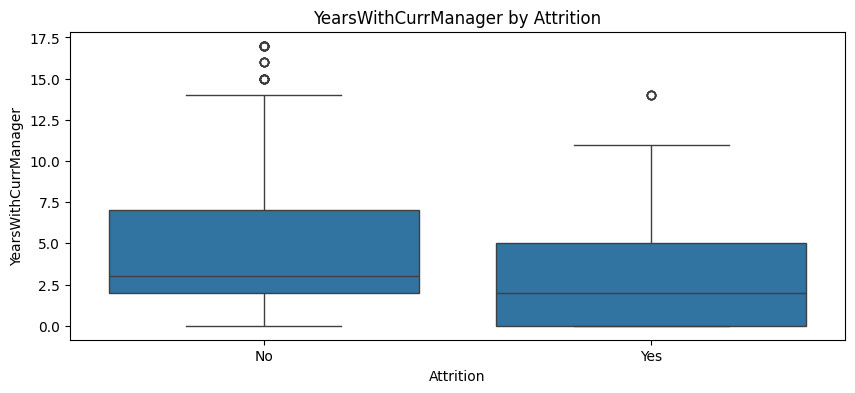

In [19]:
# Box plots for categorical vs numerical features
# Assuming 'ocean_proximity' is the categorical column
categorical_column = 'Attrition'

for column in numerical_columns:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=general_data_updated[categorical_column], y=general_data_updated[column])
    plt.title(f'{column} by {categorical_column}')
    plt.show()

##### Analyse par matrice de correlation

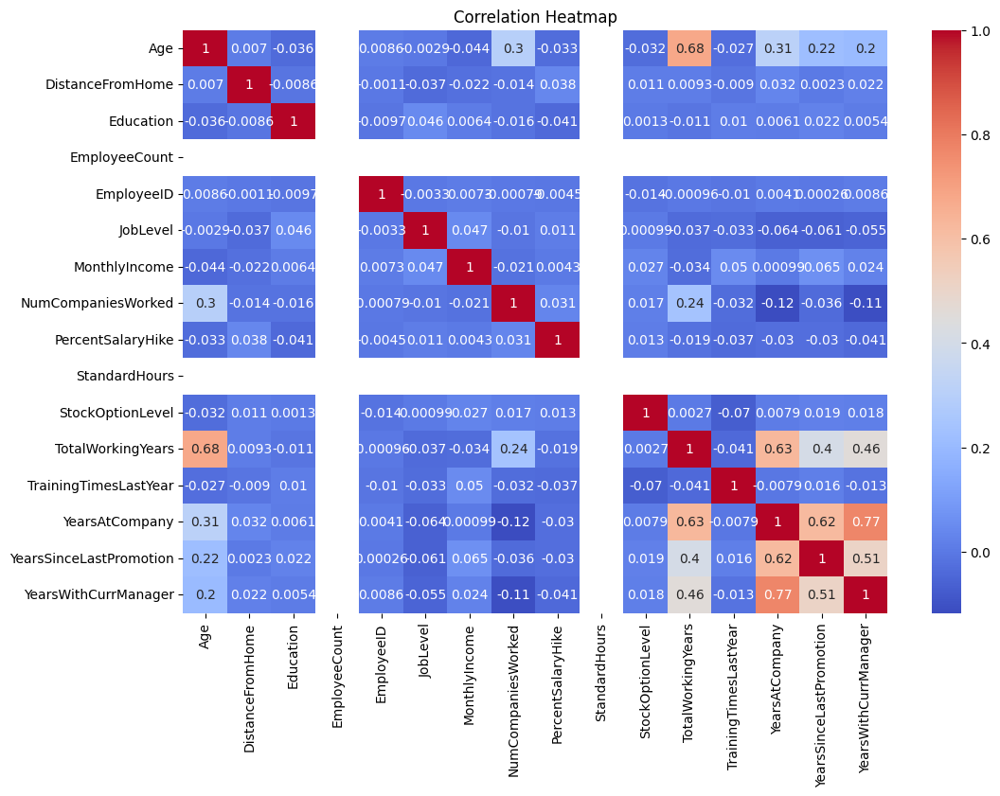

In [11]:
# Matrice de corrélation
plt.figure(figsize=(12, 8))
sns.heatmap(general_data_updated[numerical_columns].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

#### Nettoyage des données

In [12]:
general_data_clean = general_data_updated.drop(["Gender", "MaritalStatus", "EmployeeCount", "StandardHours", "Over18"], axis=1)

general_data_clean.head()

,Age,DistanceFromHome,Education,EmployeeID,JobLevel,MonthlyIncome,NumCompaniesWorked,PercentSalaryHike,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,BusinessTravel,Department,EducationField,JobRole
0,51.0,6.0,2.0,1.0,1.0,131160.0,1.0,11.0,0.0,1.0,6.0,1.0,0.0,0.0,No,Travel_Rarely,Sales,Life Sciences,Healthcare Representative
1,31.0,10.0,1.0,2.0,1.0,41890.0,0.0,23.0,1.0,6.0,3.0,5.0,1.0,4.0,Yes,Travel_Frequently,Research & Development,Life Sciences,Research Scientist
2,32.0,17.0,4.0,3.0,4.0,193280.0,1.0,15.0,3.0,5.0,2.0,5.0,0.0,3.0,No,Travel_Frequently,Research & Development,Other,Sales Executive
3,38.0,2.0,5.0,4.0,3.0,83210.0,3.0,11.0,3.0,13.0,5.0,8.0,7.0,5.0,No,Non-Travel,Research & Development,Life Sciences,Human Resources
4,32.0,10.0,1.0,5.0,1.0,23420.0,4.0,12.0,2.0,9.0,2.0,6.0,0.0,4.0,No,Travel_Rarely,Research & Development,Medical,Sales Executive


### Enquêtes de satisfaction des employées

En complément des données RH, deux enquêtes d’évaluation ont été menées en 2015 afin d’obtenir des retours sur la performance et la satisfaction des employés.

La première enquête, menée par le service RH en juin 2015, visait à recueillir des retours anonymes des employés sur leur qualité de vie au travail. Trois critères y sont évalués :
- L’environnement de travail (EnvironmentSatisfaction),
- La satisfaction liée au poste (JobSatisfaction),
- L’équilibre entre vie professionnelle et personnelle (WorkLifeBalance).

Chacun est noté sur une échelle de 1 (Faible/Mauvais) à 4 (Très élevé/Excellent).
Les réponses étaient facultatives, et les employés n’ayant pas répondu apparaissent avec la valeur "NA", ce qui nécessite un traitement spécifique des données manquantes.

#### Chargement et affichage d'un échantillion de donnée

In [13]:
# Charger le dataset
employee_survey_data = pd.read_csv('Data/employee_survey_data.csv')

# Afficher les premières lignes du dataset
employee_survey_data.head()

,EmployeeID,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance
0,1,3.0,4.0,2.0
1,2,3.0,2.0,4.0
2,3,2.0,2.0,1.0
3,4,4.0,4.0,3.0
4,5,4.0,1.0,3.0


In [14]:
# Display basic information
employee_survey_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   EmployeeID               4410 non-null   int64  
 1   EnvironmentSatisfaction  4385 non-null   float64
 2   JobSatisfaction          4390 non-null   float64
 3   WorkLifeBalance          4372 non-null   float64
dtypes: float64(3), int64(1)
memory usage: 137.9 KB


In [15]:
# Display summary statistics
employee_survey_data.describe()

,EmployeeID,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance
count,4410.000000,4385.000000,4390.000000,4372.000000
mean,2205.500000,2.723603,2.728246,2.761436
std,1273.201673,1.092756,1.101253,0.706245
min,1.000000,1.000000,1.000000,1.000000
25%,1103.250000,2.000000,2.000000,2.000000
50%,2205.500000,3.000000,3.000000,3.000000
75%,3307.750000,4.000000,4.000000,3.000000
max,4410.000000,4.000000,4.000000,4.000000


#### Vérfication du nombre de valeur null (manquante)

In [16]:
# Detection des valeurs manquantes
employee_survey_data.isnull().sum()

EmployeeID                  0
EnvironmentSatisfaction    25
JobSatisfaction            20
WorkLifeBalance            38
dtype: int64

#### Remplissage des valeurs vide

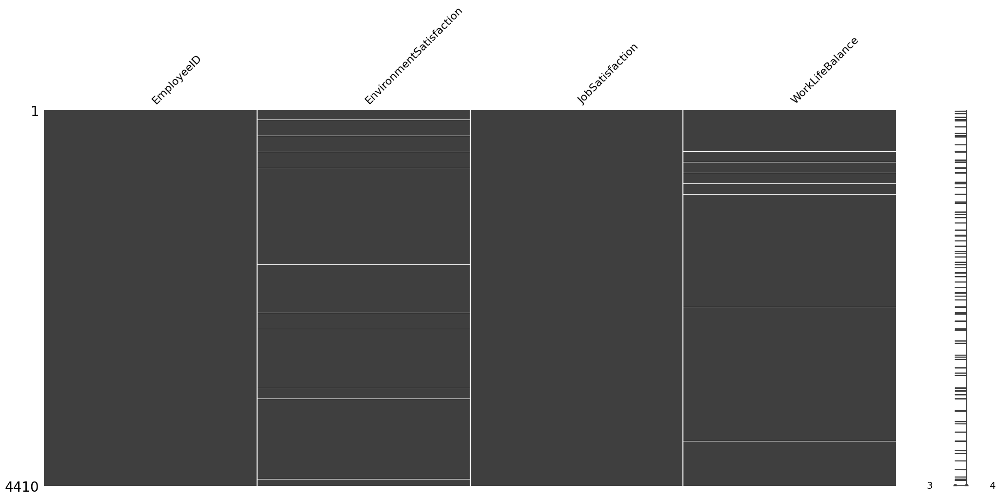

EmployeeID                 0
EnvironmentSatisfaction    0
JobSatisfaction            0
WorkLifeBalance            0
dtype: int64

In [17]:
# Visualisation des valeurs manquantes
msno.matrix(employee_survey_data)
plt.show()
employee_survey_data_updated = employee_survey_data.copy()

# Imputation des valeurs manquantes
imputer = SimpleImputer(strategy="median")

employee_survey_data_num = employee_survey_data_updated.select_dtypes(include=[np.number])
imputer.fit(employee_survey_data_num)

# Remplacement des valeurs manquantes
employee_survey_data_updated = pd.DataFrame(imputer.transform(employee_survey_data_num), columns=employee_survey_data_num.columns)

# Vérifier s'il reste des valeurs manquantes
employee_survey_data_updated.isnull().sum()

#### Fusion avec les données général 

In [18]:
# Fusion des deux datasets
merged_general_employee_data = pd.merge(employee_survey_data_updated, general_data_clean, on='EmployeeID')

# Affichage des premières lignes du dataset fusionné
merged_general_employee_data.head()

,EmployeeID,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance,Age,DistanceFromHome,Education,JobLevel,MonthlyIncome,NumCompaniesWorked,...,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,BusinessTravel,Department,EducationField,JobRole
0,1.0,3.0,4.0,2.0,51.0,6.0,2.0,1.0,131160.0,1.0,...,1.0,6.0,1.0,0.0,0.0,No,Travel_Rarely,Sales,Life Sciences,Healthcare Representative
1,2.0,3.0,2.0,4.0,31.0,10.0,1.0,1.0,41890.0,0.0,...,6.0,3.0,5.0,1.0,4.0,Yes,Travel_Frequently,Research & Development,Life Sciences,Research Scientist
2,3.0,2.0,2.0,1.0,32.0,17.0,4.0,4.0,193280.0,1.0,...,5.0,2.0,5.0,0.0,3.0,No,Travel_Frequently,Research & Development,Other,Sales Executive
3,4.0,4.0,4.0,3.0,38.0,2.0,5.0,3.0,83210.0,3.0,...,13.0,5.0,8.0,7.0,5.0,No,Non-Travel,Research & Development,Life Sciences,Human Resources
4,5.0,4.0,1.0,3.0,32.0,10.0,1.0,1.0,23420.0,4.0,...,9.0,2.0,6.0,0.0,4.0,No,Travel_Rarely,Research & Development,Medical,Sales Executive


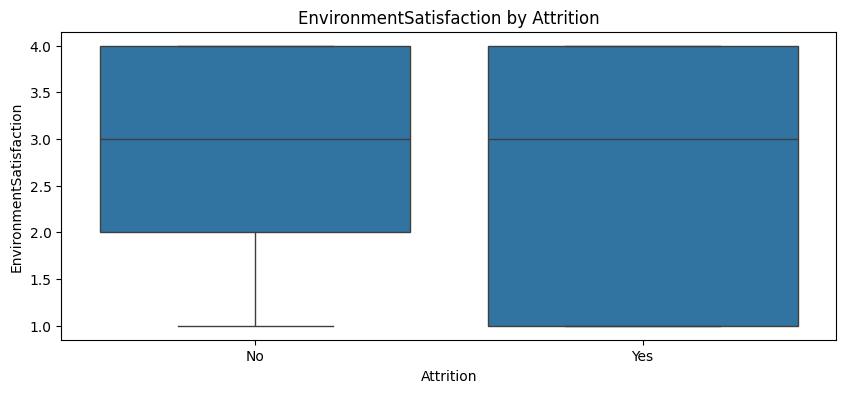

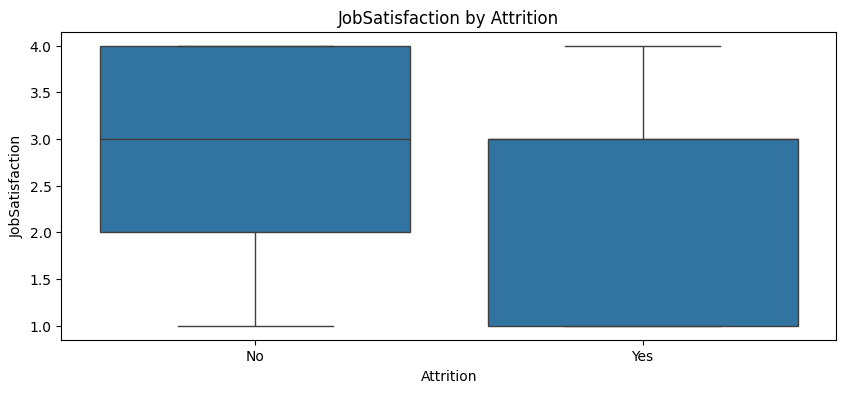

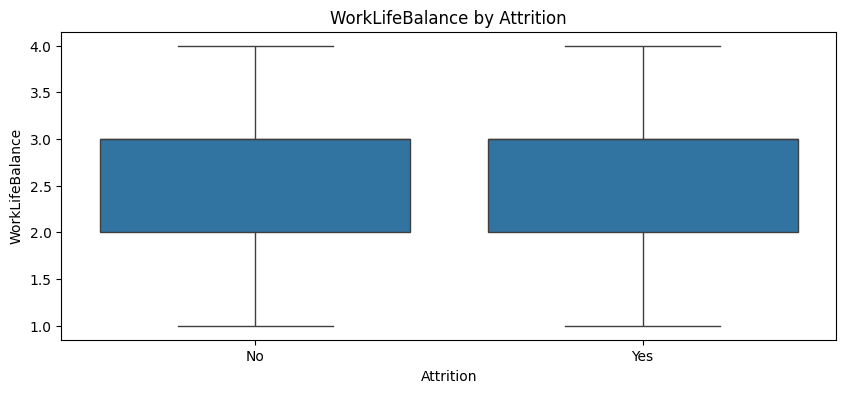

In [19]:
# Étude des données par rapport à la variable "Attrition"
numerical_columns = ["EnvironmentSatisfaction", "JobSatisfaction", "WorkLifeBalance"]
categorical_column = 'Attrition'

for column in numerical_columns:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=merged_general_employee_data[categorical_column], y=merged_general_employee_data[column])
    plt.title(f'{column} by {categorical_column}')
    plt.show()

### Évaluation des managers

La seconde enquête, réalisée en février 2015, contient l’évaluation de chaque employé par son manager. Deux aspects y sont notés :

L’implication dans le travail (JobInvolvement), mesurée sur une échelle de 1 (Faible) à 4 (Très importante).
La performance annuelle (PerformanceRating), notée de 1 (Faible) à 4 (Au-delà des attentes).

#### Chargement et affichage d'un échantillion de donnée

In [20]:
# Charger le dataset
manager_survey_data = pd.read_csv('Data/manager_survey_data.csv')

# Afficher les premières lignes du dataset
manager_survey_data.head()

,EmployeeID,JobInvolvement,PerformanceRating
0,1,3,3
1,2,2,4
2,3,3,3
3,4,2,3
4,5,3,3


In [21]:
# Display basic information
manager_survey_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   EmployeeID         4410 non-null   int64
 1   JobInvolvement     4410 non-null   int64
 2   PerformanceRating  4410 non-null   int64
dtypes: int64(3)
memory usage: 103.5 KB


In [22]:
# Display summary statistics
manager_survey_data.describe()

,EmployeeID,JobInvolvement,PerformanceRating
count,4410.000000,4410.000000,4410.000000
mean,2205.500000,2.729932,3.153741
std,1273.201673,0.711400,0.360742
min,1.000000,1.000000,3.000000
25%,1103.250000,2.000000,3.000000
50%,2205.500000,3.000000,3.000000
75%,3307.750000,3.000000,3.000000
max,4410.000000,4.000000,4.000000


#### Vérfication du nombre de valeur null (manquante)

In [23]:
# Detection des valeurs manquantes
manager_survey_data.isnull().sum()

EmployeeID           0
JobInvolvement       0
PerformanceRating    0
dtype: int64

L’analyse des valeurs manquantes sur les données d’évaluation des managers (manager_survey_data) révèle qu’aucune information n’est absente. Toutes les évaluations de JobInvolvement et PerformanceRating ont été correctement renseignées pour l’ensemble des employés.

Ainsi, aucun traitement supplémentaire n’est nécessaire pour gérer des données manquantes dans ce fichier

#### Fusion avec les données général

In [24]:
# Fusion des datasets
merged_general_employee_manager_data = pd.merge(manager_survey_data, merged_general_employee_data, on='EmployeeID')

# Affichage des premières lignes du dataset fusionné
merged_general_employee_manager_data.head()

,EmployeeID,JobInvolvement,PerformanceRating,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance,Age,DistanceFromHome,Education,JobLevel,...,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,BusinessTravel,Department,EducationField,JobRole
0,1,3,3,3.0,4.0,2.0,51.0,6.0,2.0,1.0,...,1.0,6.0,1.0,0.0,0.0,No,Travel_Rarely,Sales,Life Sciences,Healthcare Representative
1,2,2,4,3.0,2.0,4.0,31.0,10.0,1.0,1.0,...,6.0,3.0,5.0,1.0,4.0,Yes,Travel_Frequently,Research & Development,Life Sciences,Research Scientist
2,3,3,3,2.0,2.0,1.0,32.0,17.0,4.0,4.0,...,5.0,2.0,5.0,0.0,3.0,No,Travel_Frequently,Research & Development,Other,Sales Executive
3,4,2,3,4.0,4.0,3.0,38.0,2.0,5.0,3.0,...,13.0,5.0,8.0,7.0,5.0,No,Non-Travel,Research & Development,Life Sciences,Human Resources
4,5,3,3,4.0,1.0,3.0,32.0,10.0,1.0,1.0,...,9.0,2.0,6.0,0.0,4.0,No,Travel_Rarely,Research & Development,Medical,Sales Executive


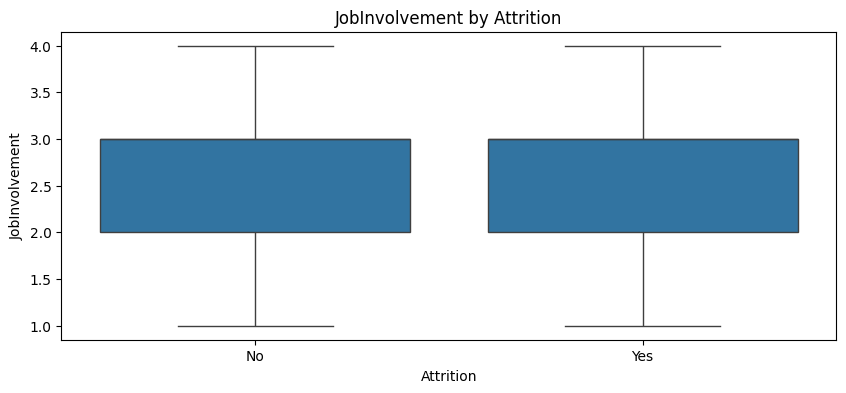

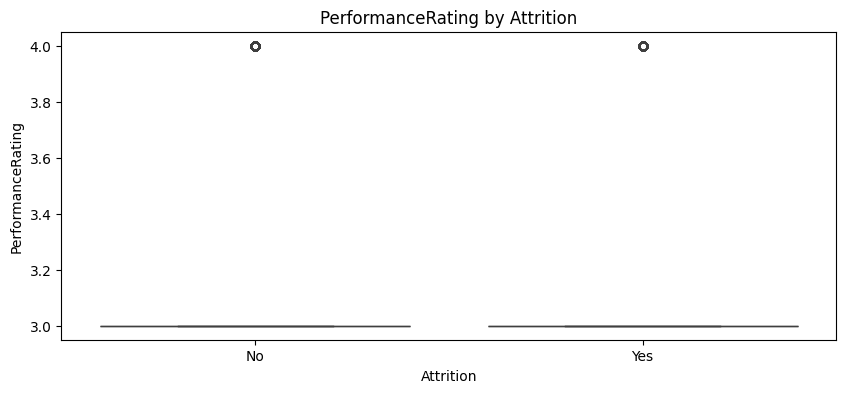

In [25]:
# Étude des données par rapport à la variable "Attrition"
numerical_columns = ["JobInvolvement", "PerformanceRating"]
categorical_column = 'Attrition'

for column in numerical_columns:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=merged_general_employee_manager_data[categorical_column], y=merged_general_employee_manager_data[column])
    plt.title(f'{column} by {categorical_column}')
    plt.show()

### TIME

Afin d’analyser les habitudes de travail des employés, la direction a fourni les horaires d’entrée et de sortie enregistrés par les badgeuses de l’entreprise. Ces données couvrent une période représentative de l’activité moyenne des différents services, allant du 1er janvier au 31 décembre 2015.

Deux fichiers distincts contiennent les horaires d’arrivée et de départ de chaque employé pour chaque journée travaillée. Ces informations permettront d’étudier les rythmes de travail, d’identifier d’éventuelles tendances (présentéisme, heures supplémentaires, retards) et d’évaluer leur impact potentiel sur la satisfaction et la rétention des employés.

#### IN TIME

In [26]:
# Charger le dataset
in_time_data = pd.read_csv('Data/in_time.csv')

# Afficher les premières lignes du dataset
in_time_data.head()

,EmployeeID,2015-01-01,2015-01-02,2015-01-05,2015-01-06,2015-01-07,2015-01-08,2015-01-09,2015-01-12,2015-01-13,...,2015-12-18,2015-12-21,2015-12-22,2015-12-23,2015-12-24,2015-12-25,2015-12-28,2015-12-29,2015-12-30,2015-12-31
0,1,NaN,2015-01-02 09:43:45,2015-01-05 10:08:48,2015-01-06 09:54:26,2015-01-07 09:34:31,2015-01-08 09:51:09,2015-01-09 10:09:25,2015-01-12 09:42:53,2015-01-13 10:13:06,...,NaN,2015-12-21 09:55:29,2015-12-22 10:04:06,2015-12-23 10:14:27,2015-12-24 10:11:35,NaN,2015-12-28 10:13:41,2015-12-29 10:03:36,2015-12-30 09:54:12,2015-12-31 10:12:44
1,2,NaN,2015-01-02 10:15:44,2015-01-05 10:21:05,NaN,2015-01-07 09:45:17,2015-01-08 10:09:04,2015-01-09 09:43:26,2015-01-12 10:00:07,2015-01-13 10:43:29,...,2015-12-18 10:37:17,2015-12-21 09:49:02,2015-12-22 10:33:51,2015-12-23 10:12:10,NaN,NaN,2015-12-28 09:31:45,2015-12-29 09:55:49,2015-12-30 10:32:25,2015-12-31 09:27:20
2,3,NaN,2015-01-02 10:17:41,2015-01-05 09:50:50,2015-01-06 10:14:13,2015-01-07 09:47:27,2015-01-08 10:03:40,2015-01-09 10:05:49,2015-01-12 10:03:47,2015-01-13 10:21:26,...,2015-12-18 10:15:14,2015-12-21 10:10:28,2015-12-22 09:44:44,2015-12-23 10:15:54,2015-12-24 10:07:26,NaN,2015-12-28 09:42:05,2015-12-29 09:43:36,2015-12-30 09:34:05,2015-12-31 10:28:39
3,4,NaN,2015-01-02 10:05:06,2015-01-05 09:56:32,2015-01-06 10:11:07,2015-01-07 09:37:30,2015-01-08 10:02:08,2015-01-09 10:08:12,2015-01-12 10:13:42,2015-01-13 09:53:22,...,2015-12-18 10:17:38,2015-12-21 09:58:21,2015-12-22 10:04:25,2015-12-23 10:11:46,2015-12-24 09:43:15,NaN,2015-12-28 09:52:44,2015-12-29 09:33:16,2015-12-30 10:18:12,2015-12-31 10:01:15
4,5,NaN,2015-01-02 10:28:17,2015-01-05 09:49:58,2015-01-06 09:45:28,2015-01-07 09:49:37,2015-01-08 10:19:44,2015-01-09 10:00:50,2015-01-12 10:29:27,2015-01-13 09:59:32,...,2015-12-18 09:58:35,2015-12-21 10:03:41,2015-12-22 10:10:30,2015-12-23 10:13:36,2015-12-24 09:44:24,NaN,2015-12-28 10:05:15,2015-12-29 10:30:53,2015-12-30 09:18:21,2015-12-31 09:41:09


In [27]:
# Display basic information
in_time_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Columns: 262 entries, EmployeeID to 2015-12-31
dtypes: float64(12), int64(1), object(249)
memory usage: 8.8+ MB


In [28]:
# Display summary statistics
in_time_data.describe()

,EmployeeID,2015-01-01,2015-01-14,2015-01-26,2015-03-05,2015-05-01,2015-07-17,2015-09-17,2015-10-02,2015-11-09,2015-11-10,2015-11-11,2015-12-25
count,4410.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
mean,2205.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,1273.201673,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,1103.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,2205.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,3307.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,4410.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [29]:
in_time_data[in_time_data.drop('EmployeeID', axis=1).columns] = in_time_data[in_time_data.drop('EmployeeID', axis=1).columns].apply(pd.to_datetime)

in_time_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Columns: 262 entries, EmployeeID to 2015-12-31
dtypes: datetime64[ns](261), int64(1)
memory usage: 8.8 MB


#### OUT TIME

In [30]:
# Charger le dataset
out_time_data = pd.read_csv('Data/out_time.csv')

# Afficher les premières lignes du dataset
out_time_data.head()

,EmployeeID,2015-01-01,2015-01-02,2015-01-05,2015-01-06,2015-01-07,2015-01-08,2015-01-09,2015-01-12,2015-01-13,...,2015-12-18,2015-12-21,2015-12-22,2015-12-23,2015-12-24,2015-12-25,2015-12-28,2015-12-29,2015-12-30,2015-12-31
0,1,NaN,2015-01-02 16:56:15,2015-01-05 17:20:11,2015-01-06 17:19:05,2015-01-07 16:34:55,2015-01-08 17:08:32,2015-01-09 17:38:29,2015-01-12 16:58:39,2015-01-13 18:02:58,...,NaN,2015-12-21 17:15:50,2015-12-22 17:27:51,2015-12-23 16:44:44,2015-12-24 17:47:22,NaN,2015-12-28 18:00:07,2015-12-29 17:22:30,2015-12-30 17:40:56,2015-12-31 17:17:33
1,2,NaN,2015-01-02 18:22:17,2015-01-05 17:48:22,NaN,2015-01-07 17:09:06,2015-01-08 17:34:04,2015-01-09 16:52:29,2015-01-12 17:36:48,2015-01-13 18:00:13,...,2015-12-18 18:31:28,2015-12-21 17:34:16,2015-12-22 18:16:35,2015-12-23 17:38:18,NaN,NaN,2015-12-28 17:08:38,2015-12-29 17:54:46,2015-12-30 18:31:35,2015-12-31 17:40:58
2,3,NaN,2015-01-02 16:59:14,2015-01-05 17:06:46,2015-01-06 16:38:32,2015-01-07 16:33:21,2015-01-08 17:24:22,2015-01-09 16:57:30,2015-01-12 17:28:54,2015-01-13 17:21:25,...,2015-12-18 17:02:23,2015-12-21 17:20:17,2015-12-22 16:32:50,2015-12-23 16:59:43,2015-12-24 16:58:25,NaN,2015-12-28 16:43:31,2015-12-29 17:09:56,2015-12-30 17:06:25,2015-12-31 17:15:50
3,4,NaN,2015-01-02 17:25:24,2015-01-05 17:14:03,2015-01-06 17:07:42,2015-01-07 16:32:40,2015-01-08 16:53:11,2015-01-09 17:19:47,2015-01-12 17:13:37,2015-01-13 17:11:45,...,2015-12-18 17:55:23,2015-12-21 16:49:09,2015-12-22 17:24:00,2015-12-23 17:36:35,2015-12-24 16:48:21,NaN,2015-12-28 17:19:34,2015-12-29 16:58:16,2015-12-30 17:40:11,2015-12-31 17:09:14
4,5,NaN,2015-01-02 18:31:37,2015-01-05 17:49:15,2015-01-06 17:26:25,2015-01-07 17:37:59,2015-01-08 17:59:28,2015-01-09 17:44:08,2015-01-12 18:51:21,2015-01-13 18:14:58,...,2015-12-18 17:52:48,2015-12-21 17:43:35,2015-12-22 18:07:57,2015-12-23 18:00:49,2015-12-24 17:59:22,NaN,2015-12-28 17:44:59,2015-12-29 18:47:00,2015-12-30 17:15:33,2015-12-31 17:42:14


In [31]:
# Display basic information
out_time_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Columns: 262 entries, EmployeeID to 2015-12-31
dtypes: float64(12), int64(1), object(249)
memory usage: 8.8+ MB


In [32]:
# Display summary statistics
out_time_data.describe()

,EmployeeID,2015-01-01,2015-01-14,2015-01-26,2015-03-05,2015-05-01,2015-07-17,2015-09-17,2015-10-02,2015-11-09,2015-11-10,2015-11-11,2015-12-25
count,4410.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
mean,2205.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,1273.201673,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,1103.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,2205.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,3307.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,4410.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [33]:
out_time_data[out_time_data.drop('EmployeeID', axis=1).columns] = out_time_data[out_time_data.drop('EmployeeID', axis=1).columns].apply(pd.to_datetime)

out_time_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Columns: 262 entries, EmployeeID to 2015-12-31
dtypes: datetime64[ns](261), int64(1)
memory usage: 8.8 MB


#### Merge time

Dans cette section, nous avons fusionné les fichiers contenant les horaires d’entrée et de sortie pour chaque employé. La durée de travail quotidienne est obtenue en soustrayant l’heure d’entrée de l’heure de sortie. Ensuite, nous calculons la moyenne du temps de travail par employé sur l’ensemble des journées enregistrées.

Enfin, cette durée moyenne est convertie en secondes afin de faciliter les analyses quantitatives. Ces informations seront précieuses pour évaluer la charge de travail et repérer d’éventuelles anomalies (sous-charge ou surmenage).

In [34]:
temp_time = in_time_data.copy()
temp_time = out_time_data.drop("EmployeeID", axis=1) - temp_time.drop("EmployeeID", axis=1)

temp_time.head()


,2015-01-01,2015-01-02,2015-01-05,2015-01-06,2015-01-07,2015-01-08,2015-01-09,2015-01-12,2015-01-13,2015-01-14,...,2015-12-18,2015-12-21,2015-12-22,2015-12-23,2015-12-24,2015-12-25,2015-12-28,2015-12-29,2015-12-30,2015-12-31
0,NaT,0 days 07:12:30,0 days 07:11:23,0 days 07:24:39,0 days 07:00:24,0 days 07:17:23,0 days 07:29:04,0 days 07:15:46,0 days 07:49:52,NaT,...,NaT,0 days 07:20:21,0 days 07:23:45,0 days 06:30:17,0 days 07:35:47,NaT,0 days 07:46:26,0 days 07:18:54,0 days 07:46:44,0 days 07:04:49
1,NaT,0 days 08:06:33,0 days 07:27:17,NaT,0 days 07:23:49,0 days 07:25:00,0 days 07:09:03,0 days 07:36:41,0 days 07:16:44,NaT,...,0 days 07:54:11,0 days 07:45:14,0 days 07:42:44,0 days 07:26:08,NaT,NaT,0 days 07:36:53,0 days 07:58:57,0 days 07:59:10,0 days 08:13:38
2,NaT,0 days 06:41:33,0 days 07:15:56,0 days 06:24:19,0 days 06:45:54,0 days 07:20:42,0 days 06:51:41,0 days 07:25:07,0 days 06:59:59,NaT,...,0 days 06:47:09,0 days 07:09:49,0 days 06:48:06,0 days 06:43:49,0 days 06:50:59,NaT,0 days 07:01:26,0 days 07:26:20,0 days 07:32:20,0 days 06:47:11
3,NaT,0 days 07:20:18,0 days 07:17:31,0 days 06:56:35,0 days 06:55:10,0 days 06:51:03,0 days 07:11:35,0 days 06:59:55,0 days 07:18:23,NaT,...,0 days 07:37:45,0 days 06:50:48,0 days 07:19:35,0 days 07:24:49,0 days 07:05:06,NaT,0 days 07:26:50,0 days 07:25:00,0 days 07:21:59,0 days 07:07:59
4,NaT,0 days 08:03:20,0 days 07:59:17,0 days 07:40:57,0 days 07:48:22,0 days 07:39:44,0 days 07:43:18,0 days 08:21:54,0 days 08:15:26,NaT,...,0 days 07:54:13,0 days 07:39:54,0 days 07:57:27,0 days 07:47:13,0 days 08:14:58,NaT,0 days 07:39:44,0 days 08:16:07,0 days 07:57:12,0 days 08:01:05


In [35]:
final_time = temp_time.copy()

final_time["avg_working_time"] = temp_time.mean(axis=1)
final_time["EmployeeID"] = in_time_data["EmployeeID"]

final_time["avg_working_time_seconds"] = final_time['avg_working_time'].dt.seconds

final_time.head()

,2015-01-01,2015-01-02,2015-01-05,2015-01-06,2015-01-07,2015-01-08,2015-01-09,2015-01-12,2015-01-13,2015-01-14,...,2015-12-23,2015-12-24,2015-12-25,2015-12-28,2015-12-29,2015-12-30,2015-12-31,avg_working_time,EmployeeID,avg_working_time_seconds
0,NaT,0 days 07:12:30,0 days 07:11:23,0 days 07:24:39,0 days 07:00:24,0 days 07:17:23,0 days 07:29:04,0 days 07:15:46,0 days 07:49:52,NaT,...,0 days 06:30:17,0 days 07:35:47,NaT,0 days 07:46:26,0 days 07:18:54,0 days 07:46:44,0 days 07:04:49,0 days 07:22:25.142241379,1,26545
1,NaT,0 days 08:06:33,0 days 07:27:17,NaT,0 days 07:23:49,0 days 07:25:00,0 days 07:09:03,0 days 07:36:41,0 days 07:16:44,NaT,...,0 days 07:26:08,NaT,NaT,0 days 07:36:53,0 days 07:58:57,0 days 07:59:10,0 days 08:13:38,0 days 07:43:08.288135593,2,27788
2,NaT,0 days 06:41:33,0 days 07:15:56,0 days 06:24:19,0 days 06:45:54,0 days 07:20:42,0 days 06:51:41,0 days 07:25:07,0 days 06:59:59,NaT,...,0 days 06:43:49,0 days 06:50:59,NaT,0 days 07:01:26,0 days 07:26:20,0 days 07:32:20,0 days 06:47:11,0 days 07:00:47.665289256,3,25247
3,NaT,0 days 07:20:18,0 days 07:17:31,0 days 06:56:35,0 days 06:55:10,0 days 06:51:03,0 days 07:11:35,0 days 06:59:55,0 days 07:18:23,NaT,...,0 days 07:24:49,0 days 07:05:06,NaT,0 days 07:26:50,0 days 07:25:00,0 days 07:21:59,0 days 07:07:59,0 days 07:11:37.242553191,4,25897
4,NaT,0 days 08:03:20,0 days 07:59:17,0 days 07:40:57,0 days 07:48:22,0 days 07:39:44,0 days 07:43:18,0 days 08:21:54,0 days 08:15:26,NaT,...,0 days 07:47:13,0 days 08:14:58,NaT,0 days 07:39:44,0 days 08:16:07,0 days 07:57:12,0 days 08:01:05,0 days 08:00:22.228571428,5,28822


#### Fusion avec les données générales

In [36]:
# Fusion des datasets
merged_global_data = pd.merge(final_time[["EmployeeID", "avg_working_time_seconds"]], merged_general_employee_manager_data, on='EmployeeID')

# Affichage des premières lignes du dataset fusionné
merged_global_data.head()

,EmployeeID,avg_working_time_seconds,JobInvolvement,PerformanceRating,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance,Age,DistanceFromHome,Education,...,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,BusinessTravel,Department,EducationField,JobRole
0,1,26545,3,3,3.0,4.0,2.0,51.0,6.0,2.0,...,1.0,6.0,1.0,0.0,0.0,No,Travel_Rarely,Sales,Life Sciences,Healthcare Representative
1,2,27788,2,4,3.0,2.0,4.0,31.0,10.0,1.0,...,6.0,3.0,5.0,1.0,4.0,Yes,Travel_Frequently,Research & Development,Life Sciences,Research Scientist
2,3,25247,3,3,2.0,2.0,1.0,32.0,17.0,4.0,...,5.0,2.0,5.0,0.0,3.0,No,Travel_Frequently,Research & Development,Other,Sales Executive
3,4,25897,2,3,4.0,4.0,3.0,38.0,2.0,5.0,...,13.0,5.0,8.0,7.0,5.0,No,Non-Travel,Research & Development,Life Sciences,Human Resources
4,5,28822,3,3,4.0,1.0,3.0,32.0,10.0,1.0,...,9.0,2.0,6.0,0.0,4.0,No,Travel_Rarely,Research & Development,Medical,Sales Executive


In [1]:
# Étude des données par rapport à la variable "Attrition"
numerical_columns = ["avg_working_time_seconds"]
categorical_column = 'Attrition'

for column in numerical_columns:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=merged_global_data[categorical_column], y=merged_global_data[column])
    plt.title(f'{column} by {categorical_column}')
    plt.show()

NameError: name 'plt' is not defined

### Analyse des données

#### Analyse bivariée

nous réalisons une analyse bivariée et une analyse par matrice de corrélation afin d'identifier les relations entre les différentes variables du jeu de données merged_global_data.

L'analyse bivariée génère des graphes de dispersion entre les variables numériques. Cela permet de visualiser les corrélations potentielles et d'identifier d'éventuelles tendances.

<Figure size 2000x400 with 0 Axes>

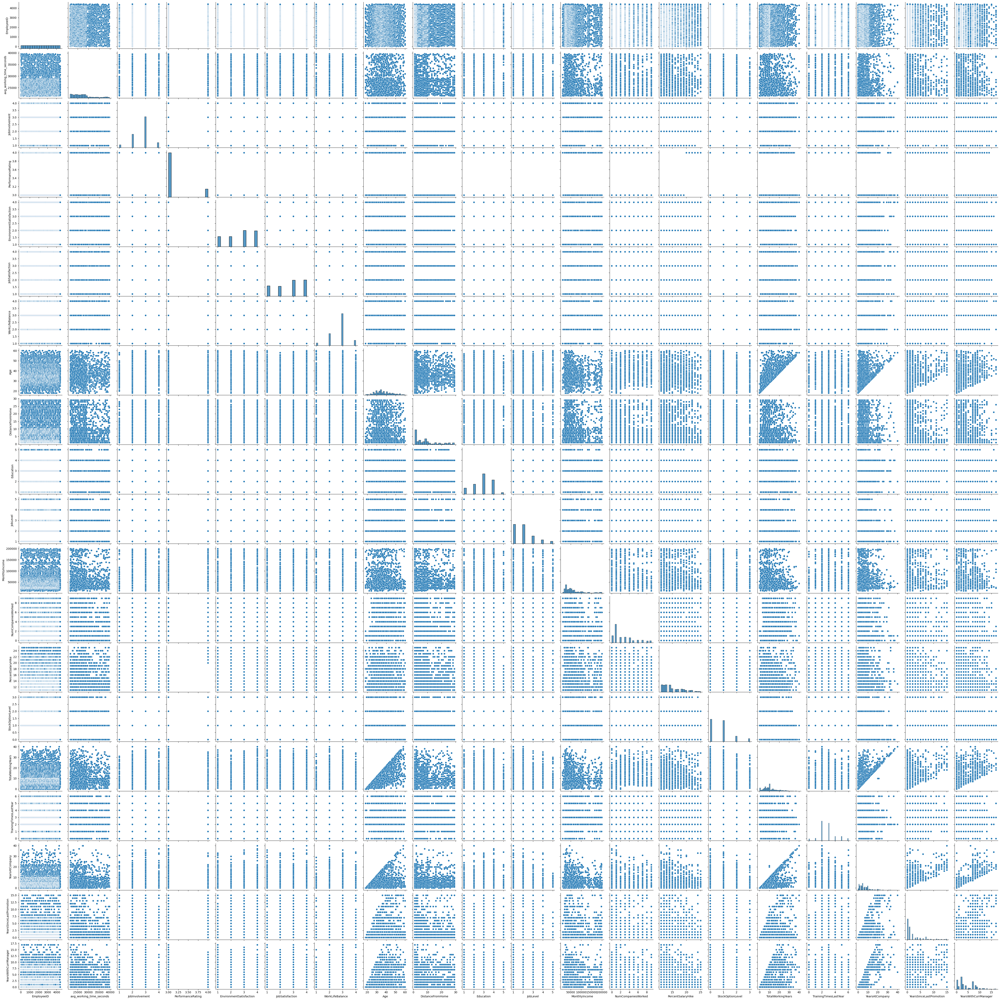

In [38]:
# Analyse bivariée de merged_global_data
plt.figure(figsize=(20, 4))
sns.pairplot(merged_global_data)
plt.show()

#### Analyse par matrice de correlation

La matrice de corrélation mesure la force et la direction des relations entre les variables. Avant de calculer cette matrice, nous devons convertir les variables catégoriques en valeurs numériques en utilisant LabelEncoder. En particulier, la colonne Attrition, qui indique si un employé a quitté l'entreprise (Yes ou No), est transformée en valeurs binaires (1 pour "Yes" et 0 pour "No").

Enfin, nous affichons la heatmap de corrélation pour mieux visualiser les relations entre les différentes variables, où les couleurs permettent de distinguer les corrélations positives et négatives. Cette analyse est essentielle pour identifier les facteurs les plus influents sur la rétention des employés.

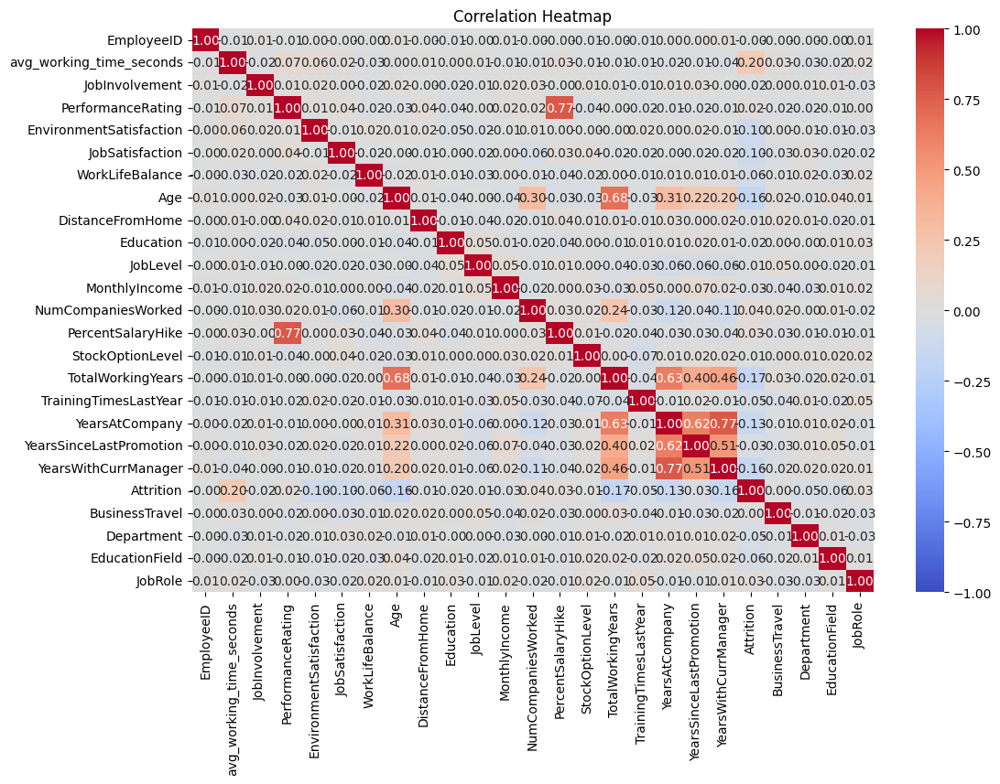

In [39]:
from sklearn.preprocessing import LabelEncoder

# Copie du dataset
merged_global_data_corel = merged_global_data.copy()

# Convertion de la colone 'Attrition' en valeurs numériques
merged_global_data_corel['Attrition'] = merged_global_data_corel['Attrition'].map({'Yes': 1, 'No': 0})

# Encodage des variables catégoriques
label_encoder = LabelEncoder()
for column in merged_global_data_corel.select_dtypes(include=['object']).columns:
    merged_global_data_corel[column] = label_encoder.fit_transform(merged_global_data_corel[column])

# Calculer la matrice de corrélation
correlation_matrix = merged_global_data_corel.corr()

# Tracer la heatmap de corrélation
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Heatmap')
plt.show()

## 3. Préparation des données

Dans cette section, nous préparons les données pour une analyse plus approfondie en encodant les variables catégorielles et en normalisant les variables numériques.

### Encodage des variables catégorielles

Tout d'abord, nous sélectionnons les colonnes catégorielles de notre dataset merged_global_data, en excluant la colonne Attrition. Ensuite, nous appliquons un encodage one-hot à ces variables à l'aide de OneHotEncoder(). Cette transformation permet de convertir chaque catégorie en une colonne binaire, facilitant ainsi leur utilisation dans des modèles d'apprentissage automatique. Nous vérifions ensuite le résultat obtenu.

In [40]:
# Sélection des colonnes catégorielles
global_data_cat = merged_global_data.select_dtypes(include=[object]).drop("Attrition", axis=1)

# Encodage one-hot des variables catégorielles

encoder = OneHotEncoder()
global_data_cat_encoded = pd.DataFrame(encoder.fit_transform(global_data_cat).toarray(), columns=encoder.get_feature_names_out(global_data_cat.columns))

# Vérification du résultat de l'encodage
global_data_cat_encoded.head()

,BusinessTravel_Non-Travel,BusinessTravel_Travel_Frequently,BusinessTravel_Travel_Rarely,Department_Human Resources,Department_Research & Development,Department_Sales,EducationField_Human Resources,EducationField_Life Sciences,EducationField_Marketing,EducationField_Medical,...,EducationField_Technical Degree,JobRole_Healthcare Representative,JobRole_Human Resources,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative
0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


### Normalisation des variables numériques

Parallèlement, nous récupérons les colonnes numériques, en excluant EmployeeID, qui est un simple identifiant. Nous appliquons ensuite une normalisation avec StandardScaler(), ce qui permet de centrer et réduire ces valeurs pour éviter que certaines variables n’aient une influence disproportionnée sur les modèles. Une vérification de la normalisation est également effectuée.

In [41]:
#Récuperation des données numériques
global_data_num = merged_global_data.select_dtypes(include=[np.number]).drop(["EmployeeID"], axis=1)

# Normalisation des colonnes numériques
scaler = StandardScaler()
global_data_num_scaled = pd.DataFrame(scaler.fit_transform(global_data_num), columns=global_data_num.columns)

# Vérification de la normalisation
global_data_num_scaled.head()

,avg_working_time_seconds,JobInvolvement,PerformanceRating,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance,Age,DistanceFromHome,Education,JobLevel,MonthlyIncome,NumCompaniesWorked,PercentSalaryHike,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsSinceLastPromotion,YearsWithCurrManager
0,-0.244050,0.379672,-0.426230,0.252200,1.156302,-1.085336,1.541369,-0.393938,-0.891688,-0.961486,1.405136,-0.678464,-1.150554,-0.932014,-1.322079,2.483396,-0.981014,-0.679146,-1.155935
1,0.013608,-1.026167,2.346151,0.252200,-0.663899,1.757749,-0.648668,0.099639,-1.868426,-0.961486,-0.491661,-1.079486,2.129306,0.241988,-0.678877,0.155707,-0.327893,-0.368715,-0.034520
2,-0.513108,0.379672,-0.426230,-0.665460,-0.663899,-2.506879,-0.539166,0.963398,1.061787,1.749610,2.725053,-0.678464,-0.057267,2.589994,-0.807517,-0.620189,-0.327893,-0.679146,-0.314873
3,-0.378371,-1.026167,-0.426230,1.169861,1.156302,0.336206,0.117845,-0.887515,2.038524,0.845911,0.386301,0.123580,-1.150554,2.589994,0.221606,1.707500,0.161947,1.493867,0.245834
4,0.227943,0.379672,-0.426230,1.169861,-1.573999,0.336206,-0.539166,0.099639,-1.868426,-0.961486,-0.884109,0.524602,-0.877232,1.415991,-0.292956,-0.620189,-0.164613,-0.679146,-0.034520


### Concaténation des données préparé

Enfin, nous concaténons les données normalisées et encodées pour former un dataset prêt à être utilisé. Nous appliquons également un encodage label (LabelEncoder()) à la variable Attrition afin de la convertir en valeurs numériques (1 pour "Yes" et 0 pour "No"). Pour conserver l'intégrité des données, nous réintégrons la colonne EmployeeID.

In [42]:
# Concatenation des colonnes numériques normalisées et des colonnes catégorielles encodées
merged_global_data_prepared = pd.concat([global_data_num_scaled, global_data_cat_encoded], axis=1)

label_encoder = LabelEncoder()

merged_global_data_prepared["Attrition"] = label_encoder.fit_transform(merged_global_data["Attrition"])#merged_global_data["Attrition"].map({'Yes': 1, 'No': 0})
merged_global_data_prepared["EmployeeID"] = merged_global_data["EmployeeID"]
#merged_global_data_prepared["avg_working_time"] = merged_global_data["avg_working_time"]

# Vérification des données préparées
merged_global_data_prepared.head()

,avg_working_time_seconds,JobInvolvement,PerformanceRating,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance,Age,DistanceFromHome,Education,JobLevel,...,JobRole_Human Resources,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,Attrition,EmployeeID
0,-0.244050,0.379672,-0.426230,0.252200,1.156302,-1.085336,1.541369,-0.393938,-0.891688,-0.961486,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1
1,0.013608,-1.026167,2.346151,0.252200,-0.663899,1.757749,-0.648668,0.099639,-1.868426,-0.961486,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1,2
2,-0.513108,0.379672,-0.426230,-0.665460,-0.663899,-2.506879,-0.539166,0.963398,1.061787,1.749610,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0,3
3,-0.378371,-1.026167,-0.426230,1.169861,1.156302,0.336206,0.117845,-0.887515,2.038524,0.845911,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,4
4,0.227943,0.379672,-0.426230,1.169861,-1.573999,0.336206,-0.539166,0.099639,-1.868426,-0.961486,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0,5


Ce processus de prétraitement des données garantit que nos variables sont sous une forme optimale pour être utilisées dans des modèles prédictifs, améliorant ainsi la qualité des analyses et des prédictions.

## 4. Application des modeles

### Séparation des carateristiques

Dans cette section, nous procédons à la séparation des caractéristiques et de la cible pour la modélisation. Nous extrayons les variables explicatives (X) en supprimant les colonnes Attrition (notre variable cible) et EmployeeID (un simple identifiant). Ensuite, nous isolons la variable cible (y), qui indique si un employé quitte l'entreprise ou non.

Nous vérifions ensuite les dimensions des jeux de données pour nous assurer que la séparation a été effectuée correctement. Enfin, nous divisons les données en un ensemble d'entraînement (70%) et un ensemble de test (30%) à l'aide de train_test_split, avec un random_state=42 pour garantir la reproductibilité des résultats. Cette préparation est essentielle pour entraîner et évaluer les modèles de manière fiable.

In [43]:
# Séparation des caractéristiques et de la cible
X = merged_global_data_prepared.drop(columns=["Attrition", "EmployeeID"], axis=1)
y = merged_global_data_prepared['Attrition']

# Vérification des dimensions
print(X.shape)
print(y.shape)


(4410, 40)
(4410,)


In [44]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

### Regression Logistique

Dans cette section, nous utilisons la régression logistique comme modèle d'apprentissage supervisé pour prédire l'attrition des employés. La régression logistique est une méthode statistique utilisée pour résoudre des problèmes de classification binaire. 

Elle repose sur la fonction sigmoïde, qui transforme une combinaison linéaire des variables explicatives en une probabilité, permettant ainsi de classer les observations dans l'une des deux catégories (ici, départ ou rétention d'un employé).

Matrice de Confusion (Régression Logistique) :
 [[1084   31]
 [ 161   47]]
Rapport de Classification (Régression Logistique) :
               precision    recall  f1-score   support

           0       0.87      0.97      0.92      1115
           1       0.60      0.23      0.33       208

    accuracy                           0.85      1323
   macro avg       0.74      0.60      0.62      1323
weighted avg       0.83      0.85      0.83      1323

AUC-ROC (Régression Logistique) :
 0.5990794239392895


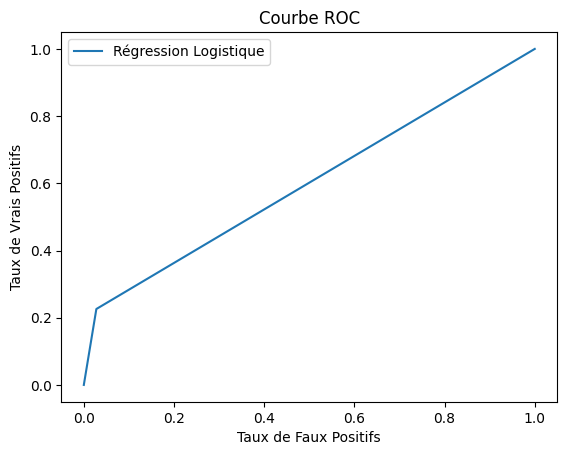

In [54]:
# Initialisation et entraînement du modèle
log_reg = LogisticRegression()
log_reg.fit(X_train, y_train)

# Prédictions
y_pred_log_reg = log_reg.predict(X_test)

# Matrice de confusion
conf_matrix_log_reg = confusion_matrix(y_test, y_pred_log_reg)
print("Matrice de Confusion (Régression Logistique) :\n", conf_matrix_log_reg)

# Rapport de classification
class_report_log_reg = classification_report(y_test, y_pred_log_reg)
print("Rapport de Classification (Régression Logistique) :\n", class_report_log_reg)

# AUC-ROC
roc_auc_log_reg = roc_auc_score(y_test, y_pred_log_reg)
print("AUC-ROC (Régression Logistique) :\n", roc_auc_log_reg)

# Courbe ROC
fpr_log_reg, tpr_log_reg, thresholds_log_reg = roc_curve(y_test, y_pred_log_reg)
plt.plot(fpr_log_reg, tpr_log_reg, label="Régression Logistique")
plt.xlabel("Taux de Faux Positifs")
plt.ylabel("Taux de Vrais Positifs")
plt.title("Courbe ROC")
plt.legend()
plt.show()

### Perceptron

Dans ce code, un modèle de Perceptron, qui est une forme simple de réseau neuronal, est utilisé pour effectuer une tâche de classification binaire. Le perceptron apprend à partir des données d'entraînement en ajustant ses poids et en les mettant à jour selon une règle d'apprentissage supervisé. Une fois le modèle entraîné, les prédictions sont générées sur un jeu de données de test. 

Matrice de Confusion (Perceptron) :
 [[971 144]
 [165  43]]
Rapport de Classification (Perceptron) :
               precision    recall  f1-score   support

           0       0.85      0.87      0.86      1115
           1       0.23      0.21      0.22       208

    accuracy                           0.77      1323
   macro avg       0.54      0.54      0.54      1323
weighted avg       0.76      0.77      0.76      1323

AUC-ROC (Perceptron) :
 0.5387913935839944


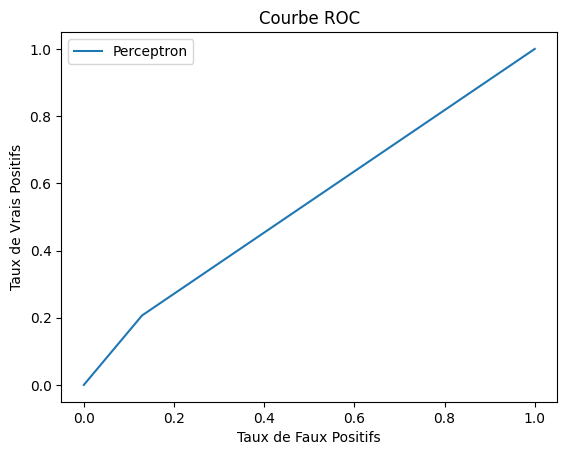

In [55]:
# Initialisation et entraînement du modèle
perceptron = Perceptron()
perceptron.fit(X_train, y_train)

# Prédictions
y_pred_perceptron = perceptron.predict(X_test)

# Matrice de confusion
conf_matrix_perceptron = confusion_matrix(y_test, y_pred_perceptron)
print("Matrice de Confusion (Perceptron) :\n", conf_matrix_perceptron)

# Rapport de classification
class_report_perceptron = classification_report(y_test, y_pred_perceptron)
print("Rapport de Classification (Perceptron) :\n", class_report_perceptron)

# AUC-ROC
roc_auc_perceptron = roc_auc_score(y_test, y_pred_perceptron)
print("AUC-ROC (Perceptron) :\n", roc_auc_perceptron)

# Courbe ROC
fpr_perceptron, tpr_perceptron, thresholds_perceptron = roc_curve(y_test, y_pred_perceptron)
plt.plot(fpr_perceptron, tpr_perceptron, label="Perceptron")
plt.xlabel("Taux de Faux Positifs")
plt.ylabel("Taux de Vrais Positifs")
plt.title("Courbe ROC")
plt.legend()
plt.show()

### SVM

Le Support Vector Machine (SVM) est un algorithme de classification supervisée qui cherche à séparer les différentes classes de données par un hyperplan optimal, maximisant la marge entre les points de chaque classe. Il est particulièrement efficace pour des problèmes de classification non linéaire grâce à l’utilisation de noyaux (kernel), ce qui permet de transformer les données dans un espace de dimension supérieure. 

Dans ce code, un modèle SVM avec une option probability=True est utilisé, ce qui permet de calculer les probabilités des classes plutôt que des prédictions catégorielles directes. Une fois le modèle entraîné sur les données d'entraînement (X_train, y_train), il prédit les classes des données de test (X_test).

Matrice de Confusion (SVM) :
 [[1110    5]
 [ 108  100]]
Rapport de Classification (SVM) :
               precision    recall  f1-score   support

           0       0.91      1.00      0.95      1115
           1       0.95      0.48      0.64       208

    accuracy                           0.91      1323
   macro avg       0.93      0.74      0.80      1323
weighted avg       0.92      0.91      0.90      1323

AUC-ROC (SVM) :
 0.7381424629182477


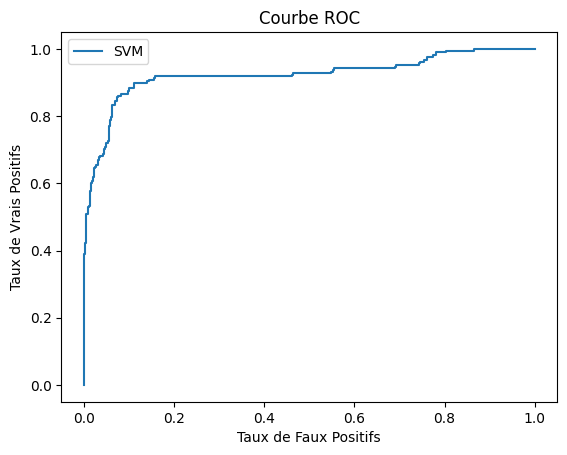

In [56]:
# Initialisation et entraînement du modèle
svm = SVC(probability=True)
svm.fit(X_train, y_train)

# Prédictions
y_pred_svm = svm.predict(X_test)

# Matrice de confusion
conf_matrix_svm = confusion_matrix(y_test, y_pred_svm)
print("Matrice de Confusion (SVM) :\n", conf_matrix_svm)

# Rapport de classification
class_report_svm = classification_report(y_test, y_pred_svm)
print("Rapport de Classification (SVM) :\n", class_report_svm)

# AUC-ROC
roc_auc_svm = roc_auc_score(y_test, y_pred_svm)
print("AUC-ROC (SVM) :\n", roc_auc_svm)

# Courbe ROC
fpr_svm, tpr_svm, thresholds_svm = roc_curve(y_test, svm.predict_proba(X_test)[:,1])
plt.plot(fpr_svm, tpr_svm, label="SVM")
plt.xlabel("Taux de Faux Positifs")
plt.ylabel("Taux de Vrais Positifs")
plt.title("Courbe ROC")
plt.legend()
plt.show()

### Naive Bayes

Naive Bayes est une méthode de classification probabiliste fondée sur le théorème de Bayes, qui suppose que les caractéristiques des données sont indépendantes les unes des autres, d'où le terme "naïve". Malgré cette hypothèse d'indépendance parfois irréaliste, il est particulièrement performant dans des contextes de classification de texte ou avec des données peu corrélées. Dans ce code, un modèle GaussianNB est utilisé, adapté aux cas où les caractéristiques suivent une distribution normale (gaussienne).

Matrice de Confusion (Naive Bayes) :
 [[982 133]
 [122  86]]
Rapport de Classification (Naive Bayes) :
               precision    recall  f1-score   support

           0       0.89      0.88      0.89      1115
           1       0.39      0.41      0.40       208

    accuracy                           0.81      1323
   macro avg       0.64      0.65      0.64      1323
weighted avg       0.81      0.81      0.81      1323

AUC-ROC (Naive Bayes) :
 0.647089513625388


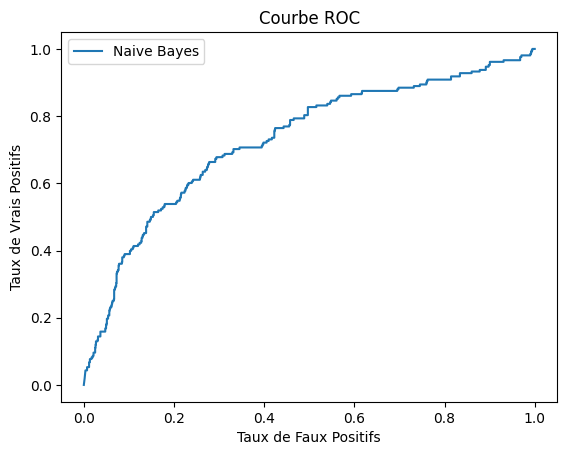

In [48]:
# Initialisation et entraînement du modèle
nb = GaussianNB()
nb.fit(X_train, y_train)

# Prédictions
y_pred_nb = nb.predict(X_test)

# Matrice de confusion
conf_matrix_nb = confusion_matrix(y_test, y_pred_nb)
print("Matrice de Confusion (Naive Bayes) :\n", conf_matrix_nb)

# Rapport de classification
class_report_nb = classification_report(y_test, y_pred_nb)
print("Rapport de Classification (Naive Bayes) :\n", class_report_nb)

# AUC-ROC
roc_auc_nb = roc_auc_score(y_test, y_pred_nb)
print("AUC-ROC (Naive Bayes) :\n", roc_auc_nb)

# Courbe ROC
fpr_nb, tpr_nb, thresholds_nb = roc_curve(y_test, nb.predict_proba(X_test)[:,1])
plt.plot(fpr_nb, tpr_nb, label="Naive Bayes")
plt.xlabel("Taux de Faux Positifs")
plt.ylabel("Taux de Vrais Positifs")
plt.title("Courbe ROC")
plt.legend()
plt.show()

### Arbre de decision

Le Decision Tree (arbre de décision) est un modèle de classification supervisée qui divise les données en fonction de critères de plus en plus précis à chaque nœud, créant ainsi une structure en arbre. Chaque feuille de cet arbre représente une classe, et les décisions sont prises en fonction des valeurs des caractéristiques des données. L'avantage des arbres de décision réside dans leur simplicité d'interprétation, car on peut visualiser le processus de décision. 

Matrice de Confusion (Decision Tree) :
 [[1095   20]
 [  32  176]]
Rapport de Classification (Decision Tree) :
               precision    recall  f1-score   support

           0       0.97      0.98      0.98      1115
           1       0.90      0.85      0.87       208

    accuracy                           0.96      1323
   macro avg       0.93      0.91      0.92      1323
weighted avg       0.96      0.96      0.96      1323

AUC-ROC (Decision Tree) :
 0.9141083132114523


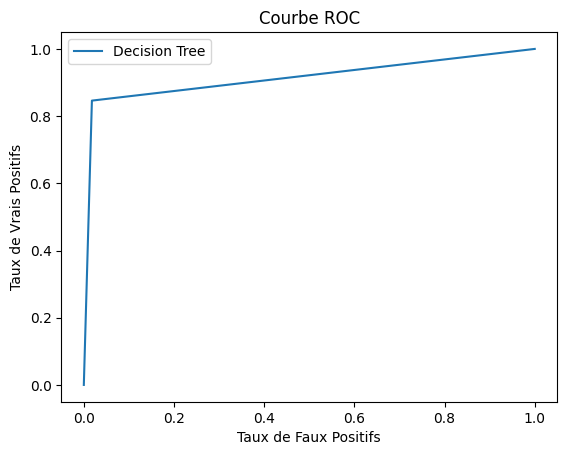

In [49]:
# Initialisation et entraînement du modèle
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train, y_train)

# Prédictions
y_pred_tree = tree_model.predict(X_test)

# Matrice de confusion
conf_matrix_tree = confusion_matrix(y_test, y_pred_tree)
print("Matrice de Confusion (Decision Tree) :\n", conf_matrix_tree)

# Rapport de classification
class_report_tree = classification_report(y_test, y_pred_tree)
print("Rapport de Classification (Decision Tree) :\n", class_report_tree)

# AUC-ROC
roc_auc_tree = roc_auc_score(y_test, y_pred_tree)
print("AUC-ROC (Decision Tree) :\n", roc_auc_tree)

# Courbe ROC
y_proba_tree = tree_model.predict_proba(X_test)[:, 1]
fpr_tree, tpr_tree, thresholds_tree = roc_curve(y_test, y_proba_tree)
plt.figure()
plt.plot(fpr_tree, tpr_tree, label="Decision Tree")
plt.xlabel("Taux de Faux Positifs")
plt.ylabel("Taux de Vrais Positifs")
plt.title("Courbe ROC")
plt.legend()
plt.show()

### Random forest

Random Forest est un ensemble d'arbres de décision où plusieurs arbres sont créés et entraînés de manière indépendante à partir de sous-ensembles aléatoires des données. Chaque arbre dans la forêt effectue des prédictions, et la prédiction finale est obtenue par un vote majoritaire (pour la classification). Cette approche permet de réduire le risque de sur-apprentissage (overfitting) souvent rencontré avec des arbres de décision individuels, tout en améliorant la précision du modèle. 

Matrice de Confusion (Random Forest) :
 [[1115    0]
 [  22  186]]
Rapport de Classification (Random Forest) :
               precision    recall  f1-score   support

           0       0.98      1.00      0.99      1115
           1       1.00      0.89      0.94       208

    accuracy                           0.98      1323
   macro avg       0.99      0.95      0.97      1323
weighted avg       0.98      0.98      0.98      1323

AUC-ROC (Random Forest) :
 0.9471153846153846


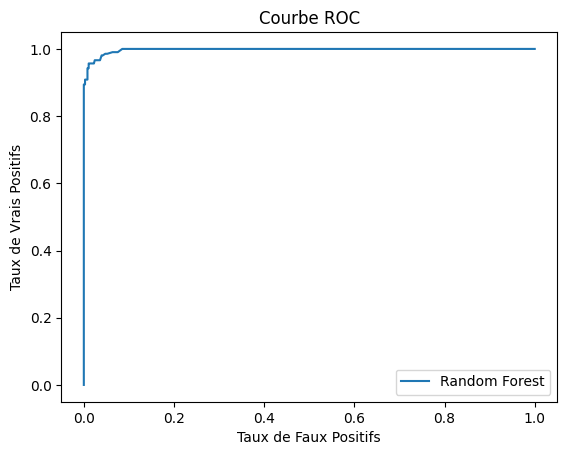

In [50]:
# Initialisation et entraînement du modèle
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Prédictions
y_pred_rf = rf_model.predict(X_test)

# Matrice de confusion
conf_matrix_rf = confusion_matrix(y_test, y_pred_rf)
print("Matrice de Confusion (Random Forest) :\n", conf_matrix_rf)

# Rapport de classification
class_report_rf = classification_report(y_test, y_pred_rf)
print("Rapport de Classification (Random Forest) :\n", class_report_rf)

# AUC-ROC
roc_auc_rf = roc_auc_score(y_test, y_pred_rf)
print("AUC-ROC (Random Forest) :\n", roc_auc_rf)

# Courbe ROC
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]
fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_test, y_proba_rf)
plt.figure()
plt.plot(fpr_rf, tpr_rf, label="Random Forest")
plt.xlabel("Taux de Faux Positifs")
plt.ylabel("Taux de Vrais Positifs")
plt.title("Courbe ROC")
plt.legend()
plt.show()

### Comparaison des modeles

Nous initialisons les modèles de classification énnoncés plus tôt. Ensuite, nous entraînons chaque modèle sur le jeu de données d'entraînement (X_train, y_train) et effectuons des prédictions sur le jeu de test (X_test). Toutes les prédictions sont stockées dans un dictionnaire predictions avec le nom du modèle comme clé, ce qui nous permet de comparer les résultats de chaque modèle de manière simple et organisée.

In [65]:
models = {
    "Perceptron": Perceptron(),
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=42),
    "SVM": SVC(probability=True),
    "NaiveBayes": GaussianNB(),
    "DecisionTree": DecisionTreeClassifier(random_state=42),
    "RandomForest": RandomForestClassifier(n_estimators=100, random_state=42)
}

# Entraînement et prédiction
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)

Nous définissons une fonction display_metrics qui affiche les résultats d'évaluation d'un modèle donné. Cette fonction prend en entrée les vraies valeurs (y_test), les prédictions (y_pred), ainsi que le nom du modèle. Elle affiche la matrice de confusion et le rapport de classification pour chaque modèle. Ensuite, pour chaque prédiction stockée dans le dictionnaire predictions, nous appelons cette fonction afin d'afficher les métriques associées à chaque modèle de manière structurée, ce qui nous permet de comparer facilement les performances de tous les modèles utilisés.

In [66]:
# Fonction pour afficher les résultats
def display_metrics(y_test, y_pred, model_name):
      print("Modèle :", model_name)
      print("Matrice de Confusion :\n", confusion_matrix(y_test, y_pred))
      print("Rapport de Classification :\n", classification_report(y_test, y_pred))

# Calcul des métriques
for name, y_pred in predictions.items():
    display_metrics(y_test, y_pred, name)
    print("\n")

Modèle : Perceptron
Matrice de Confusion :
 [[677  63]
 [115  27]]
Rapport de Classification :
               precision    recall  f1-score   support

           0       0.85      0.91      0.88       740
           1       0.30      0.19      0.23       142

    accuracy                           0.80       882
   macro avg       0.58      0.55      0.56       882
weighted avg       0.77      0.80      0.78       882



Modèle : LogisticRegression
Matrice de Confusion :
 [[727  13]
 [112  30]]
Rapport de Classification :
               precision    recall  f1-score   support

           0       0.87      0.98      0.92       740
           1       0.70      0.21      0.32       142

    accuracy                           0.86       882
   macro avg       0.78      0.60      0.62       882
weighted avg       0.84      0.86      0.82       882



Modèle : SVM
Matrice de Confusion :
 [[739   1]
 [ 78  64]]
Rapport de Classification :
               precision    recall  f1-score   support

Nous affichons les matrices de confusion pour chaque modèle de classification en utilisant la bibliothèque seaborn et matplotlib. Pour chaque modèle dans predictions, nous calculons la matrice de confusion entre les vraies valeurs (y_test) et les prédictions (y_pred). Nous utilisons ensuite sns.heatmap pour afficher cette matrice sous forme de carte thermique, avec des couleurs qui permettent de visualiser rapidement les performances du modèle. Par ailleurs, les valeurs TP (True Positives), TN (True Negatives), FP (False Positives) et FN (False Negatives) sont extraites de la matrice et ajoutées sur le graphique pour une meilleure lisibilité. Enfin, le titre de chaque graphique indique le nom du modèle correspondant, permettant ainsi une comparaison visuelle des matrices de confusion de tous les modèles.

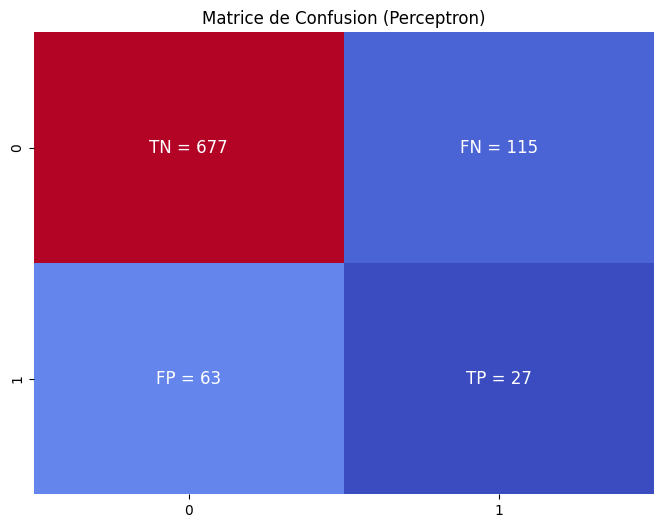

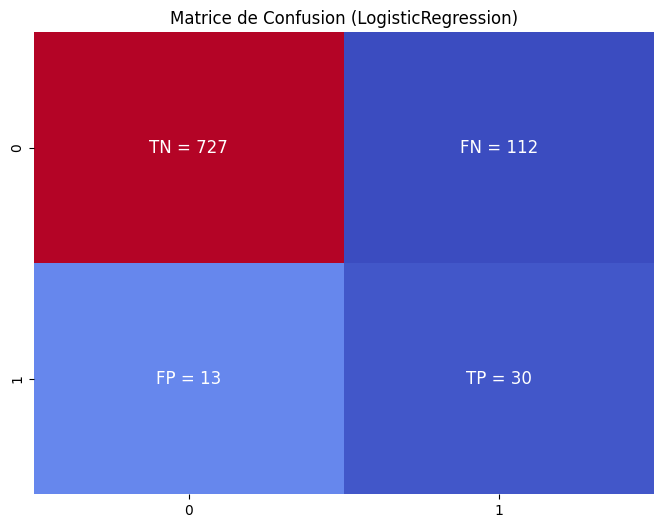

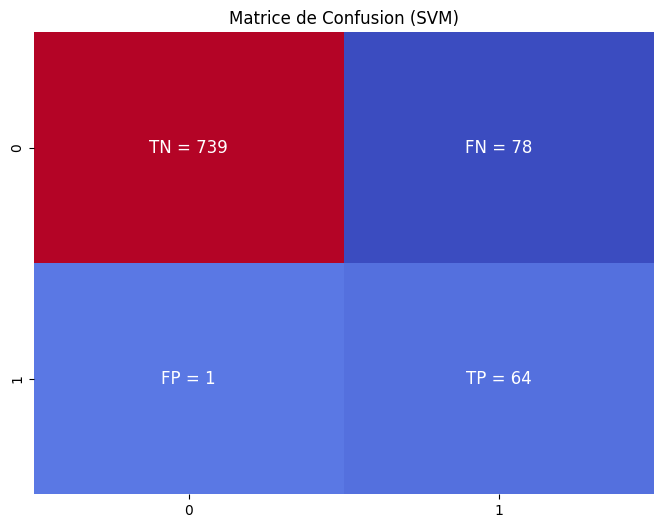

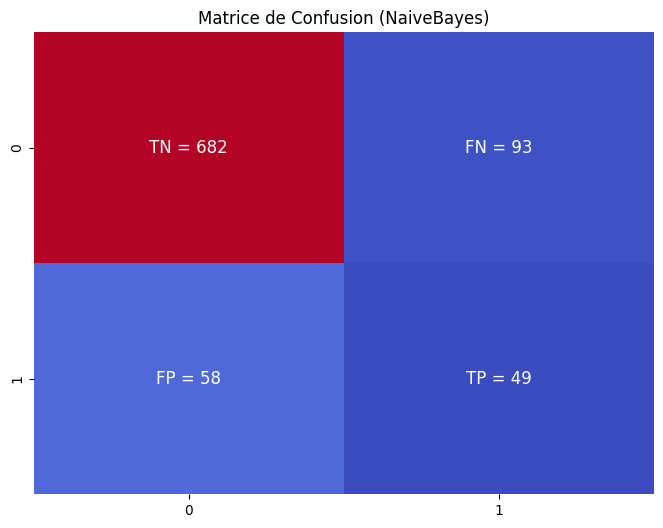

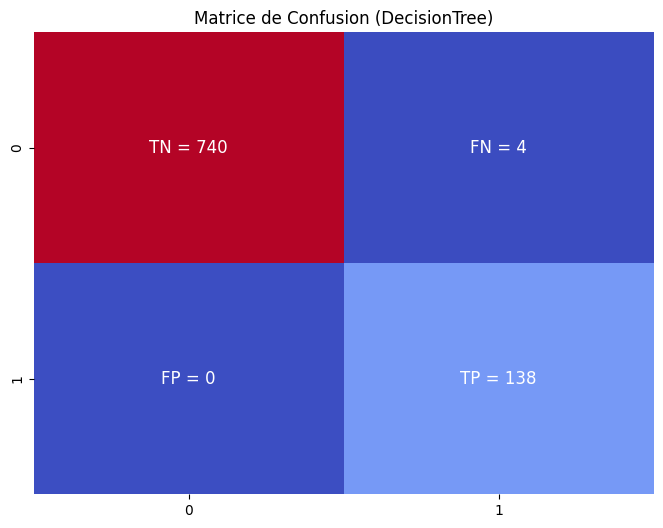

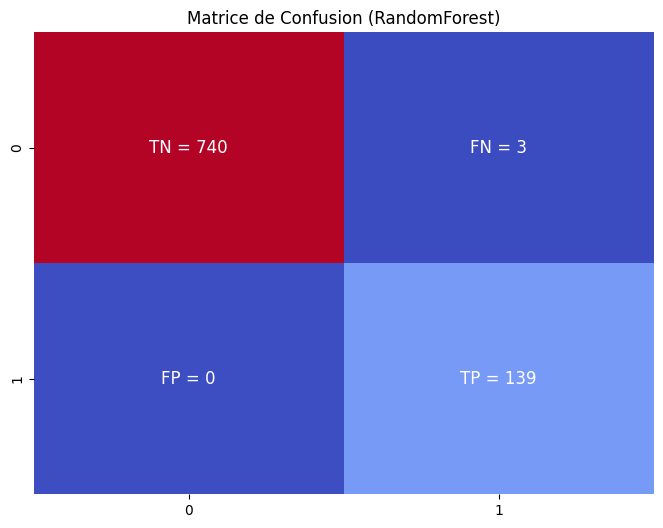

In [67]:
for name, y_pred in predictions.items():
      conf_matrix = confusion_matrix(y_test, y_pred)
      plt.figure(figsize=(8, 6))
      sns.heatmap(conf_matrix, annot=False, fmt="d", cmap="coolwarm", cbar=False)
      # Calcul des valeurs TP, TN, FP, FN
      TN, FP, FN, TP = conf_matrix.ravel()
      # Ajout des valeurs TP, TN, FP, FN sur le graphique
      plt.text(0.5, 0.5, f'TN = {TN}', ha='center', va='center', color='white', fontsize=12)
      plt.text(0.5, 1.5, f'FP = {FP}', ha='center', va='center', color='white', fontsize=12)
      plt.text(1.5, 0.5, f'FN = {FN}', ha='center', va='center', color='white', fontsize=12)
      plt.text(1.5, 1.5, f'TP = {TP}', ha='center', va='center', color='white', fontsize=12)
      plt.title(f"Matrice de Confusion ({name})")
      plt.show()

Nous traçons deux types de courbes pour évaluer les performances des modèles de classification : la courbe de précision-rappel et la courbe ROC.

Tout d'abord, nous traçons la courbe de précision-rappel, qui permet de visualiser le compromis entre la précision (le pourcentage de prédictions correctes parmi celles classées positives) et le rappel (le pourcentage d'instances positives correctement identifiées). Nous calculons la précision et le rappel pour chaque modèle en utilisant precision_recall_curve et affichons ces courbes pour tous les modèles qui disposent de la méthode predict_proba, indiquant qu'ils retournent les probabilités des classes.

Ensuite, nous traçons la courbe ROC (Receiver Operating Characteristic), qui montre la relation entre le taux de faux positifs (FPR) et le taux de vrais positifs (TPR) pour différents seuils de classification. Nous calculons cette courbe pour chaque modèle avec roc_curve et affichons l'AUC (Area Under the Curve), qui mesure la capacité du modèle à discriminer les classes. Les courbes sont ensuite comparées en traçant la diagonale (ligne pointillée) qui représente un modèle aléatoire.

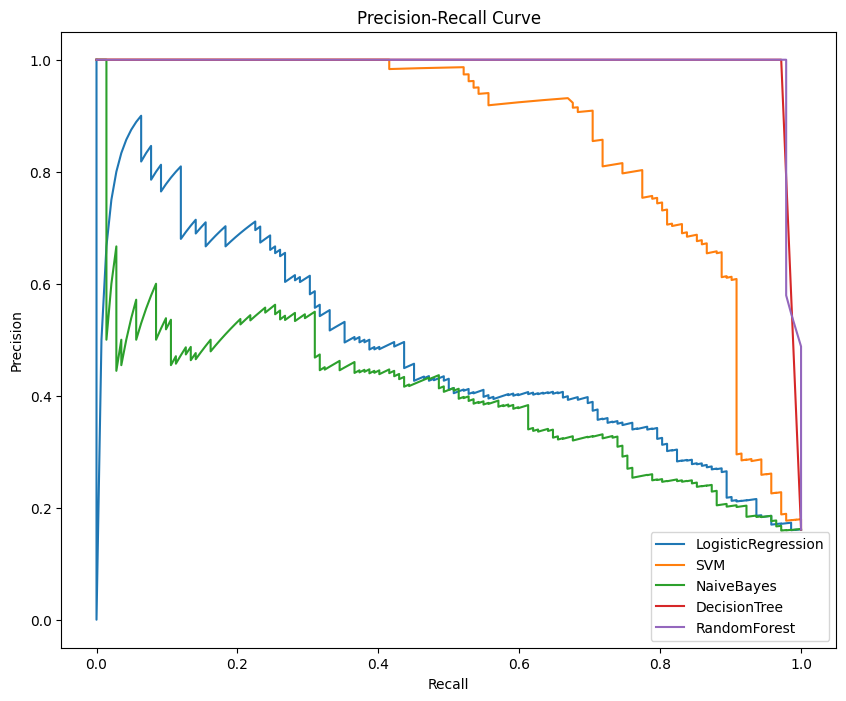

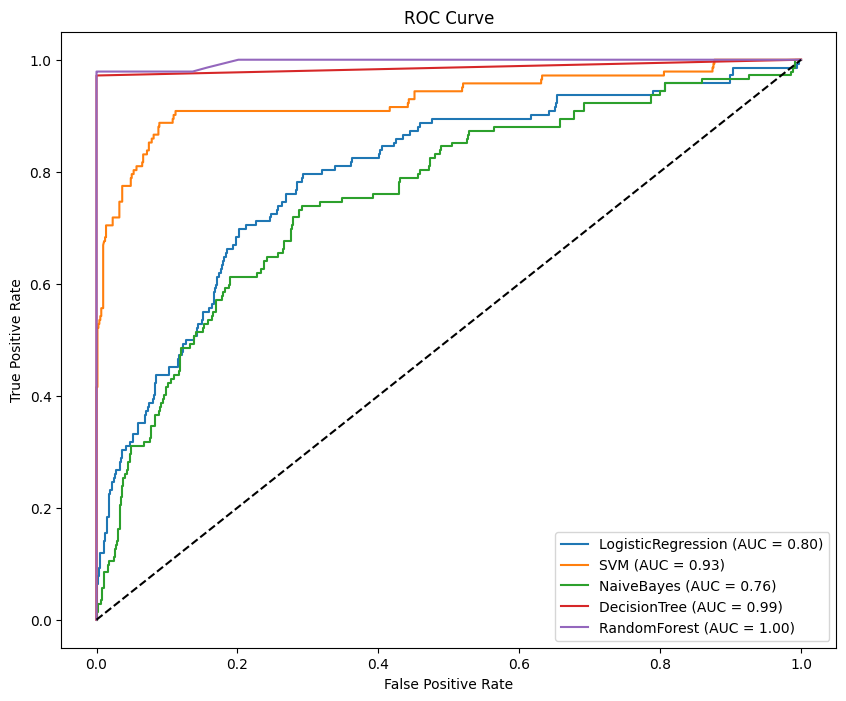

In [68]:
# Tracer les courbes de Précision-Rappel
plt.figure(figsize=(10, 8))

for name, model in models.items():
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test)[:, 1]
        precision, recall, _ = precision_recall_curve(y_test, y_proba)
        plt.plot(recall, precision, label=f"{name}")

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

# Tracer les courbes ROC
plt.figure(figsize=(10, 8))

for name, model in models.items():
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        auc = roc_auc_score(y_test, y_proba)
        plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.2f})")

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

Dans cette section, nous calculons les scores de précision, rappel, et F1 pour chaque modèle de classification à l’aide des prédictions stockées dans predictions. Ces métriques sont essentielles pour évaluer la performance d'un modèle, particulièrement dans les contextes où les classes sont déséquilibrées. La précision mesure la proportion de prédictions positives correctes, le rappel évalue la capacité du modèle à identifier toutes les instances positives, et le score F1 fournit une moyenne harmonique entre précision et rappel, ce qui est utile lorsque l'on souhaite un compromis entre ces deux critères.

Les scores calculés pour chaque modèle sont ensuite stockés dans une dataframe score_df avec les noms des modèles, ce qui permet une comparaison facile. Nous utilisons ensuite un diagramme en boîte (box plot) pour visualiser la distribution de ces scores à travers tous les modèles. Ce type de graphique permet de mettre en évidence les variations, les médianes, ainsi que les éventuels outliers pour chaque métrique. Cette représentation graphique est utile pour comparer les modèles de manière rapide et visuelle sur ces critères spécifiques.

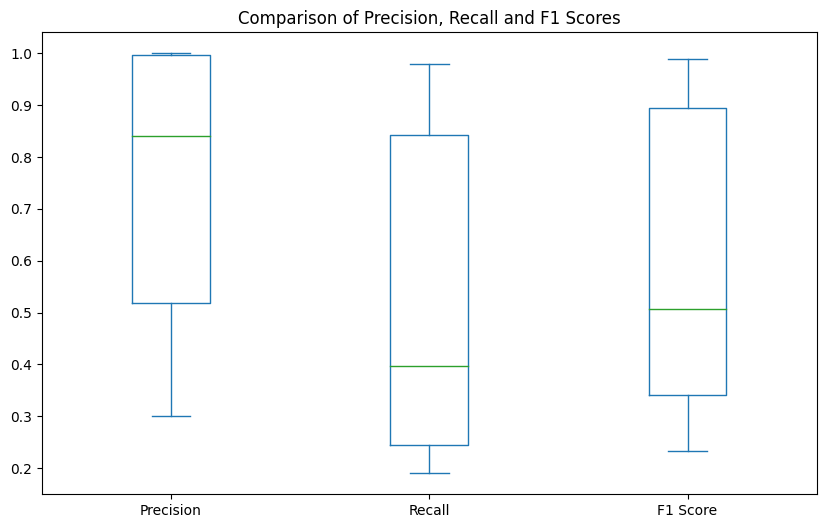

In [70]:
precision_scores = []
recall_scores = []
f1_scores = []

for name, y_pred in predictions.items():
    precision_scores.append(precision_score(y_test, y_pred))
    recall_scores.append(recall_score(y_test, y_pred))
    f1_scores.append(f1_score(y_test, y_pred))
    
score_df = pd.DataFrame({
    'Model': models.keys(),
    'Precision': precision_scores,
    'Recall': recall_scores,
    'F1 Score': f1_scores
})

score_df.plot(kind='box', figsize=(10, 6))
plt.title("Comparison of Precision, Recall and F1 Scores")
plt.show()


Nous calculons plusieurs métriques de performance (précision, rappel, F1 score et AUC) pour chaque modèle de classification, puis nous organisons ces scores dans une dataframe pour une présentation claire et structurée. Pour chaque modèle dans predictions, nous récupérons les prédictions, calculons les scores de précision, rappel, et F1 à l'aide des fonctions correspondantes, puis calculons également l'AUC (Area Under the Curve) si le modèle dispose de la méthode predict_proba (qui permet de retourner les probabilités des classes). Si cette méthode est disponible, l'AUC est calculé à partir des probabilités des classes positives, sinon la valeur de l'AUC est laissée comme None.

Les résultats sont ensuite ajoutés dans une liste sous forme de dictionnaires, avec le nom du modèle et les scores associés. Cette liste est convertie en une dataframe scores_df à l'aide de pandas, ce qui permet de comparer facilement les différentes métriques de performance pour chaque modèle. Enfin, cette dataframe est imprimée, offrant une vue d'ensemble des performances des modèles sur les différentes métriques, facilitant ainsi l'analyse comparative.

In [71]:
scores = []

for name, y_pred in predictions.items():
    y_proba = models[name].predict_proba(X_test)[:, 1] if hasattr(models[name], "predict_proba") else None
    auc_score = roc_auc_score(y_test, y_proba) if y_proba is not None else None
    scores.append({
        'Model': name,
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'AUC': auc_score
    })

scores_df = pd.DataFrame(scores)
print(scores_df)


                Model  Precision    Recall  F1 Score       AUC
0          Perceptron   0.300000  0.190141  0.232759       NaN
1  LogisticRegression   0.697674  0.211268  0.324324  0.795889
2                 SVM   0.984615  0.450704  0.618357  0.929934
3          NaiveBayes   0.457944  0.345070  0.393574  0.758203
4        DecisionTree   1.000000  0.971831  0.985714  0.985915
5        RandomForest   1.000000  0.978873  0.989324  0.996446


Dans cette section, nous mesurons le temps d'entraînement et le temps de prédiction pour chaque modèle de classification. Pour chaque modèle, nous enregistrons le temps nécessaire pour entraîner le modèle sur le jeu de données d'entraînement (X_train, y_train) en utilisant la fonction time.time() pour obtenir l'heure de départ, puis calculons la différence avec l'heure de fin après l'appel à fit. Nous répétons ce processus pour mesurer le temps de prédiction en utilisant la méthode predict sur le jeu de test (X_test).

Les résultats de ces mesures (temps d'entraînement et de prédiction) sont stockés dans des listes, puis organisés dans une dataframe time_df avec les noms des modèles, ce qui nous permet de comparer facilement l'efficacité en termes de temps de chaque modèle. Enfin, cette dataframe est imprimée, offrant ainsi une vue d'ensemble des performances temporelles des différents modèles, ce qui peut être utile pour évaluer non seulement la précision mais aussi la rapidité des modèles dans un cadre opérationnel.

In [72]:
training_times = []
prediction_times = []

for name, model in models.items():
    start_time = time.time()
    model.fit(X_train, y_train)
    training_times.append(time.time() - start_time)

    start_time = time.time()
    model.predict(X_test)
    prediction_times.append(time.time() - start_time)
    
time_df = pd.DataFrame({
    'Model': models.keys(),
    'Training Time (s)': training_times,
    'Prediction Time (s)': prediction_times
})
print(time_df)

                Model  Training Time (s)  Prediction Time (s)
0          Perceptron           0.034999             0.007008
1  LogisticRegression           0.164613             0.004994
2                 SVM           5.158738             0.241668
3          NaiveBayes           0.012003             0.002997
4        DecisionTree           0.057028             0.002995
5        RandomForest           1.079120             0.048024


## Optimisation

Dans ce code, nous utilisons une approche d'optimisation bayésienne pour ajuster les hyperparamètres d'un modèle de forêt aléatoire (RandomForestClassifier) et ainsi maximiser ses performances sur un jeu de données donné.

Nous commençons par diviser le jeu de données en deux ensembles distincts : un ensemble d'entraînement et un ensemble de test, en utilisant train_test_split. L'option stratify=y permet de maintenir une distribution similaire des classes dans ces deux ensembles, ce qui est crucial pour garantir que les résultats sont représentatifs de l'ensemble des données.

Ensuite, nous définissons un espace de recherche des hyperparamètres à optimiser. Ce dernier inclut des paramètres tels que le nombre d'arbres (n_estimators), la profondeur maximale des arbres (max_depth), ainsi que des critères comme le nombre minimum d'échantillons pour diviser un nœud (min_samples_split). D’autres paramètres sont également définis, tels que le nombre de caractéristiques à considérer à chaque division (max_features) et si le bootstrap est activé ou non (bootstrap).

Une fois l'espace de recherche défini, nous créons un modèle de forêt aléatoire standard en utilisant RandomForestClassifier, avec un état aléatoire fixé pour garantir la reproductibilité des résultats. L'optimisation bayésienne est ensuite réalisée avec BayesSearchCV, un algorithme d'optimisation qui effectue une recherche intelligente des hyperparamètres en utilisant la validation croisée. Ce processus repose sur la maximisation de l'accuracy, une métrique couramment utilisée pour évaluer les modèles de classification. La recherche est effectuée sur plusieurs itérations, et la méthode utilise la parallélisation via n_jobs pour accélérer les calculs.

L'optimisation est ensuite lancée sur l'ensemble d'entraînement avec opt.fit(X_train, y_train), ce qui permet de trouver la combinaison optimale d'hyperparamètres. Une fois l'optimisation terminée, nous récupérons les meilleurs hyperparamètres à l'aide de opt.best_params_ et appliquons ces derniers pour définir le modèle final. Ce modèle est ensuite évalué sur l'ensemble de test à l'aide de l'accuracy, ce qui nous donne une mesure concrète de ses performances sur de nouvelles données.

In [73]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Définir l'espace de recherche des hyperparamètres
param_space = {
    "n_estimators": Integer(50, 500),  # Nombre d'arbres
    "max_depth": Integer(5, 50),  # Profondeur maximale des arbres
    "min_samples_split": Integer(2, 20),  # Minimum d'échantillons pour diviser un nœud
    "min_samples_leaf": Integer(1, 10),  # Minimum d'échantillons dans une feuille
    "max_features": Categorical(["sqrt", "log2", None]),  # Nombre de features à utiliser
    "bootstrap": Categorical([True, False])  # Bootstrap activé/désactivé
}

# 5. Créer le modèle
rf = RandomForestClassifier(random_state=42)

# 6. Optimisation bayésienne
opt = BayesSearchCV(
    rf,
    param_space,
    n_iter=30,  # Nombre d'itérations pour l'optimisation
    cv=5,  # Validation croisée à 5 folds
    scoring="accuracy",  # Score basé sur l'accuracy
    n_jobs=1,  # Utilisation de tous les cœurs du CPU
    random_state=42
)

# 7. Entraîner l'optimisation
opt.fit(X_train, y_train)

# 8. Meilleurs hyperparamètres et performance
print("Meilleurs hyperparamètres :", opt.best_params_)
best_model = opt.best_estimator_

# 9. Évaluer le modèle sur les données de test
y_pred = best_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy sur le test set :", accuracy)

Meilleurs hyperparamètres : OrderedDict([('bootstrap', False), ('max_depth', 36), ('max_features', 'sqrt'), ('min_samples_leaf', 1), ('min_samples_split', 2), ('n_estimators', 368)])
Accuracy sur le test set : 0.9965986394557823


Nous appliquons une optimisation bayésienne sur un modèle de forêt aléatoire (RandomForestClassifier), mais cette fois-ci, nous nous concentrons sur l'optimisation du F1-score plutôt que de l'accuracy.

Nous commençons par créer un scorer personnalisé en utilisant make_scorer et en définissant que nous souhaitons optimiser le F1-score en mode "binaire" (pour les problèmes de classification binaire). Le F1-score est une métrique qui prend en compte à la fois la précision et le rappel, et est particulièrement utile lorsque les classes sont déséquilibrées, car il pénalise davantage les erreurs de classification pour les classes minoritaires.

L'optimisation bayésienne est ensuite configurée via BayesSearchCV, où l'on spécifie l’espace de recherche des hyperparamètres, le nombre d’itérations de l’optimisation (n_iter=30), le nombre de folds pour la validation croisée (cv=5), et le F1-score comme fonction de score (scoring=f1_scorer). Cette optimisation cherche donc la meilleure combinaison d'hyperparamètres qui maximisera le F1-score plutôt que l'accuracy. Comme dans l'exemple précédent, nous utilisons l'option n_jobs=1 pour contrôler l’utilisation des ressources CPU.

Une fois l’optimisation effectuée avec la méthode fit, les meilleurs hyperparamètres sont récupérés via opt.best_params_. Nous appliquons ensuite ces hyperparamètres au modèle, que nous stockons dans best_model. Ce modèle est alors évalué sur l'ensemble de test, et nous calculons le F1-score à l'aide de f1_score, ce qui permet de mesurer les performances du modèle de manière plus précise dans le cas de données déséquilibrées.

In [74]:
# Création du f1 scorer
f1_scorer = make_scorer(f1_score, average="binary")

# 6. Optimisation bayésienne
opt = BayesSearchCV(
    rf,
    param_space,
    n_iter=30,
    cv=5,
    scoring=f1_scorer,  # Utiliser f1-score
    n_jobs=1,
    random_state=42
)

# 7. Entraîner l'optimisation
opt.fit(X_train, y_train)

# 8. Meilleurs hyperparamètres et performance
print("Meilleurs hyperparamètres :", opt.best_params_)
best_model = opt.best_estimator_

# 9. Évaluer le modèle sur les données de test
y_pred = best_model.predict(X_test)
f1 = f1_score(y_test, y_pred)
print("F1-score sur le test set :", f1)

c:\Users\theot\AppData\Local\Programs\Python\Python310\lib\site-packages\skopt\optimizer\optimizer.py:517: UserWarning: The objective has been evaluated at point [False, 47, 'sqrt', 1, 2, 500] before, using random point [False, 15, 'sqrt', 4, 13, 136]
  warnings.warn(


Meilleurs hyperparamètres : OrderedDict([('bootstrap', False), ('max_depth', 46), ('max_features', 'sqrt'), ('min_samples_leaf', 1), ('min_samples_split', 4), ('n_estimators', 500)])
F1-score sur le test set : 0.9893238434163701


Nous pouvons récupérer les hyperparamètres du modèle rf_mode.

In [75]:
rf_model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

Pour finir, nous utilisons le modèle RandomForestClassifier avec les meilleurs hyperparamètres obtenus lors de l'optimisation bayésienne, en les passant au modèle grâce à l'argument **opt.best_params_. Après l'initialisation, nous entraînons le modèle sur les données d'apprentissage à l'aide de la méthode fit(). Une fois l'entraînement terminé, nous utilisons le modèle pour prédire les résultats sur l'ensemble de test via la méthode predict(). Les performances du modèle sont ensuite évaluées à travers plusieurs métriques. Nous commençons par générer la matrice de confusion, qui nous permet de visualiser les vrais et faux positifs et négatifs, suivie du rapport de classification qui fournit des informations sur la précision, le rappel et le score F1 du modèle. Ensuite, nous calculons l'AUC-ROC pour mesurer la capacité du modèle à distinguer les classes, avant de tracer la courbe ROC, qui montre la relation entre le taux de faux positifs et le taux de vrais positifs à différents seuils de classification. Cette série de métriques et de visualisations permet d’évaluer la performance du modèle Random Forest de manière complète et détaillée.

Matrice de Confusion (Random Forest) :
 [[740   0]
 [  3 139]]
Rapport de Classification (Random Forest) :
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       740
           1       1.00      0.98      0.99       142

    accuracy                           1.00       882
   macro avg       1.00      0.99      0.99       882
weighted avg       1.00      1.00      1.00       882

AUC-ROC (Random Forest) :
 0.9894366197183099


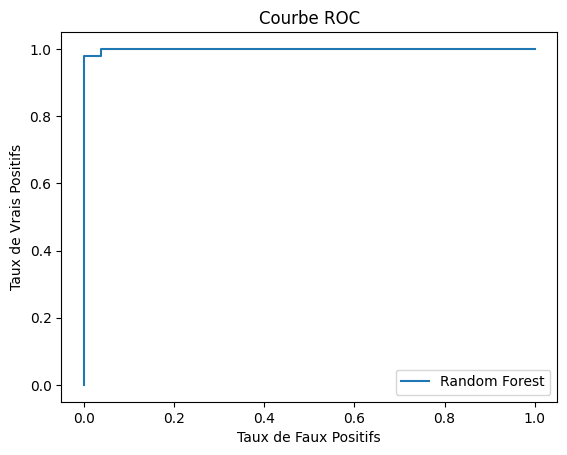

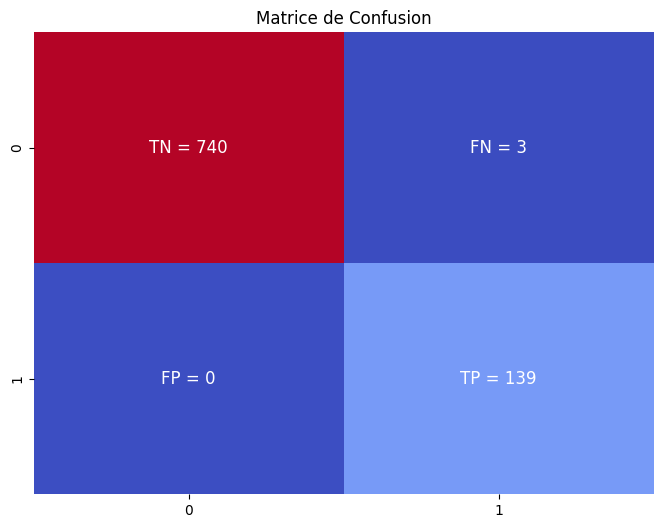

In [76]:
# Initialisation et entraînement du modèle
rf_model = RandomForestClassifier(**opt.best_params_, random_state=42)
rf_model.fit(X_train, y_train)

# Prédictions
y_pred_rf = rf_model.predict(X_test)

# Matrice de confusion
conf_matrix_rf = confusion_matrix(y_test, y_pred_rf)
print("Matrice de Confusion (Random Forest) :\n", conf_matrix_rf)

# Rapport de classification
class_report_rf = classification_report(y_test, y_pred_rf)
print("Rapport de Classification (Random Forest) :\n", class_report_rf)

# AUC-ROC
roc_auc_rf = roc_auc_score(y_test, y_pred_rf)
print("AUC-ROC (Random Forest) :\n", roc_auc_rf)

# Courbe ROC
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]
fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_test, y_proba_rf)
plt.figure()
plt.plot(fpr_rf, tpr_rf, label="Random Forest")
plt.xlabel("Taux de Faux Positifs")
plt.ylabel("Taux de Vrais Positifs")
plt.title("Courbe ROC")
plt.legend()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_rf, annot=False, fmt="d", cmap="coolwarm", cbar=False)
# Calcul des valeurs TP, TN, FP, FN
TN, FP, FN, TP = conf_matrix_rf.ravel()
# Ajout des valeurs TP, TN, FP, FN sur le graphique
plt.text(0.5, 0.5, f'TN = {TN}', ha='center', va='center', color='white', fontsize=12)
plt.text(0.5, 1.5, f'FP = {FP}', ha='center', va='center', color='white', fontsize=12)
plt.text(1.5, 0.5, f'FN = {FN}', ha='center', va='center', color='white', fontsize=12)
plt.text(1.5, 1.5, f'TP = {TP}', ha='center', va='center', color='white', fontsize=12)
plt.title(f"Matrice de Confusion")
plt.show()